# Video Indexing of Clean and Dirty Places
## RNN vs. LSTM vs. GRU on frame-level CNN features (PyTorch, Google Colab)

This notebook is a complete, re-runnable pipeline for the assignment: it audits your phone videos, extracts frames at a fixed rate, computes frame-level features with a pretrained CNN, trains **RNN**, **LSTM** and **GRU** video classifiers on exactly the same features and split, evaluates them, studies the effect of **sequence length** and **frame-sampling rate**, tests whether **temporal information really helps** compared with single frames, and finally builds a **video index with a search interface** (and an optional timestamp extension).

**Runtime:** Colab with a GPU (T4 is enough). Feature extraction is the only slow step (it runs once and is cached in Drive); all recurrent models then train on the cached features in seconds.

### How the assignment tasks map to this notebook

| Assignment task | Section |
|---|---|
| 1. Video dataset collection, labels, train/val/test | 1 (audit, label check, duplicates, metadata), 3 (leakage-free split) |
| 2. Preprocessing: fixed-rate frames, resize, normalise, pretrained CNN features, one feature sequence per video | 2 |
| 3. RNN, LSTM, GRU models on the same features | 4 |
| 4. Training, evaluation (accuracy, precision, recall, F1, confusion matrices), inference time, parameters, sequence length and sampling rate | 5 (training), 6 (evaluation), 9 (length and rate), 10 (time and parameters) |
| 5. Comparative analysis, temporal information vs. single frames, robustness, error analysis | 7 (is temporal information used?), 8 (cross-validation), 11 (robustness and errors) |
| 6. Video indexing and retrieval, optional timestamps | 12 |
| Deliverables | 13 |

### Design decisions you should know about
* **Same everything.** One frozen CNN backbone (ResNet-50, ImageNet), one set of cached features, one split, one training recipe; the three models differ **only in the recurrent cell** (`nn.RNN`, `nn.LSTM`, `nn.GRU`) inside an otherwise identical network.
* **Leakage-free split.** Videos filmed minutes apart usually show the same place. If the videos carry a creation time, they are grouped into capture sessions and **whole sessions go to one split**, stratified by class.
* **Small data, so more than one split.** With a few dozen videos, a test set holds only a handful of videos. Besides the required fixed train/val/test split (5 training seeds), the notebook runs **grouped K-fold cross-validation** so that *every* video gets an out-of-sample prediction. Robustness and error analyses use these predictions.
* **Video-level vs. timestamp-level.** The labels describe **whole videos**. The classifiers therefore answer "is this video clean or dirty?". Where in the video the dirty place appears is a different question for which there are **no labels**; the optional timestamp extension (Section 12) is a demonstration, not a measured result, unless you add timestamp annotations.
* **Frame sampling.** Frames are decoded once at 4 frames per second (fps). Lower rates (2, 1, 0.5 fps) are exact subsets of these frames, so all rates share the same pixels.
* **Windows.** Models read windows of `T` consecutive sampled frames. Training draws random windows; at test time the video is covered by consecutive windows and the window probabilities are averaged, so the whole video is always used.

> **What has not been run for you.** I wrote this without access to your GPU or your videos, so I could only check that the code parses and that the window, split, metric and timestamp functions work on synthetic data. The first run may need small fixes. Risky steps are wrapped so that a failure is reported and the rest still runs.

## 0. Setup

In [ ]:
!pip -q install timm scikit-learn scipy gradio opencv-python-headless tqdm

In [ ]:
import os, sys, io, json, math, time, random, shutil, copy, gc, re, hashlib, subprocess, warnings
from pathlib import Path
from collections import Counter, defaultdict
from time import perf_counter

import numpy as np
import pandas as pd
import cv2
import torch, torch.nn as nn, torch.nn.functional as F
import timm
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, confusion_matrix, roc_auc_score, roc_curve,
                             average_precision_score, balanced_accuracy_score, brier_score_loss)
from scipy import stats

warnings.filterwarnings('ignore')
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
assert DEVICE == 'cuda', 'Please switch the Colab runtime to a GPU.'
GPU_NAME = torch.cuda.get_device_name(0)
print('torch', torch.__version__, '| timm', timm.__version__, '| opencv', cv2.__version__, '| GPU:', GPU_NAME)
print('ffmpeg available:', shutil.which('ffmpeg') is not None, '| ffprobe available:', shutil.which('ffprobe') is not None)

torch 2.11.0+cu130 | timm 1.0.30 | opencv 4.14.0 | GPU: Tesla T4
ffmpeg available: True | ffprobe available: True


In [ ]:
# -----------------------------------------------------------------------------
# Paths and global settings
# -----------------------------------------------------------------------------
QUICK_TEST = False     # True: tiny runs (few epochs, one seed, fewer studies). Results go to a separate folder.
from google.colab import drive
drive.mount('/content/drive')

ROOT        = Path('/content/drive/MyDrive/Clean_Dirty_Video_Dataset')
VIDEO_DIR   = ROOT / 'videos'
OUT         = ROOT / ('Experiments_quicktest' if QUICK_TEST else 'Experiments')
FEAT_DIR    = ROOT / 'features'                    # cached frame features (shared by all experiments)
LOCAL       = Path('/content/video_work'); LOCAL.mkdir(exist_ok=True, parents=True)
DIRS = {k: OUT / k for k in ('models', 'figures', 'tables', 'predictions')}
for d in list(DIRS.values()) + [FEAT_DIR]: d.mkdir(parents=True, exist_ok=True)

SEED_SPLIT     = 42                   # seed of the fixed split
SEEDS          = [42] if QUICK_TEST else [42, 43, 44, 45, 46]   # training seeds on the fixed split
CV_FOLDS       = 3 if QUICK_TEST else 7
BASE_FPS       = 4                    # frames are decoded at this rate; lower rates are subsets (1 / 2 / 4 / 8 strides)
FPS, T_WIN     = 2, 16                # default sampling rate and window length (frames)
FPS_LIST       = [1, 4] if QUICK_TEST else [0.5, 1, 2, 4]
T_LIST         = [4, 16] if QUICK_TEST else [2, 4, 8, 16, 32, 64]
FRAME_SIZE     = 224                  # frames are resized to FRAME_SIZE x FRAME_SIZE (no cropping) before the CNN
THUMB_LONG     = 192                  # long side of the stored thumbnails (used for display and image statistics)
TEST_FRAC = VAL_FRAC = 0.15
SESSION_GAP_MIN = 10
CLASS_NAMES    = ['Clean', 'Dirty']   # label 0 = Clean, label 1 = Dirty (positive class)
SWAP_FOLDER_LABELS = None             # None = decide automatically (Section 1.3); True / False = your explicit decision
TRANSCODE_FOR_WEB = True              # make small H.264 copies (480p, no audio) for the search interface and the GitHub export
VEXT = {'.mp4', '.mov', '.avi', '.mkv', '.m4v', '.webm', '.3gp'}

def seed_everything(s): random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
def savefig(name): plt.savefig(DIRS['figures'] / f'{name}.png', dpi=150, bbox_inches='tight')
seed_everything(SEED_SPLIT)
print('video folder found:', VIDEO_DIR.exists(), '| sub-folders:', [p.name for p in VIDEO_DIR.iterdir()] if VIDEO_DIR.exists() else None)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
video folder found: True | sub-folders: ['Dirty', 'Clean']


## 1. Video dataset audit (Task 1)

### 1.1 What is in the two folders?

To make decoding fast (Drive is slow for random access), the videos are copied once to the local disk of the Colab machine. For every video the notebook records duration, frame rate, resolution, rotation tag, file size and (if present) the **creation time** stored in the file, which is later used to detect capture sessions.

In [ ]:
def probe_creation_time(path):
    try:
        r = subprocess.run(['ffprobe', '-v', 'quiet', '-print_format', 'json', '-show_format', str(path)], capture_output=True, text=True, timeout=30)
        v = json.loads(r.stdout).get('format', {}).get('tags', {}).get('creation_time')
        return pd.to_datetime(v).tz_localize(None) if v else pd.NaT
    except Exception: return pd.NaT

def probe_video(path):
    cap = cv2.VideoCapture(str(path)); ok = cap.isOpened()
    if not ok: return None
    fps = cap.get(cv2.CAP_PROP_FPS) or float('nan'); n = cap.get(cv2.CAP_PROP_FRAME_COUNT); W = cap.get(cv2.CAP_PROP_FRAME_WIDTH); H = cap.get(cv2.CAP_PROP_FRAME_HEIGHT)
    rot = cap.get(cv2.CAP_PROP_ORIENTATION_META) if hasattr(cv2, 'CAP_PROP_ORIENTATION_META') else float('nan')
    fourcc = int(cap.get(cv2.CAP_PROP_FOURCC)); codec = ''.join(chr((fourcc >> 8 * i) & 0xFF) for i in range(4)); cap.release()
    return dict(fps=fps, n_frames=n, duration_s=n / fps if fps and fps == fps else float('nan'), W=int(W), H=int(H), rotation_tag=rot, codec=codec)

LOCAL_VIDEOS = LOCAL / 'videos'
rows, unreadable = [], []
for cls_dir in sorted(p for p in VIDEO_DIR.iterdir() if p.is_dir()):
    fs = sorted(p for p in cls_dir.iterdir() if p.suffix.lower() in VEXT)
    print(f'{cls_dir.name}: {len(fs)} videos | types {dict(Counter(p.suffix.lower() for p in fs))} | first: {fs[0].name if fs else None}')
    for p in tqdm(fs, desc=cls_dir.name, leave=False):
        dst = LOCAL_VIDEOS / cls_dir.name / p.name; dst.parent.mkdir(parents=True, exist_ok=True)
        if not dst.exists(): shutil.copy(p, dst)
        meta = probe_video(dst)
        if meta is None: unreadable.append(str(p)); continue
        rows.append(dict(video_id=f'{cls_dir.name}/{p.name}', name=p.name, folder=cls_dir.name, folder_label=0 if cls_dir.name.lower().startswith('clean') else 1,
                         path=str(dst), size_mb=p.stat().st_size / 2**20, creation_time=probe_creation_time(dst), md5=hashlib.md5(open(dst, 'rb').read()).hexdigest(), **meta))
VID = pd.DataFrame(rows)
print('\nreadable videos:', len(VID), '| unreadable:', unreadable)
display(VID.groupby('folder').agg(videos=('name', 'count'), total_min=('duration_s', lambda s: s.sum() / 60), median_s=('duration_s', 'median'), min_s=('duration_s', 'min'),
                                   max_s=('duration_s', 'max'), median_fps=('fps', 'median'), median_mb=('size_mb', 'median')).round(2))
print('resolutions:', dict(Counter(f'{w}x{h}' for w, h in zip(VID.W, VID.H)).most_common(5)))
print('rotation tags:', dict(Counter(VID.rotation_tag)), '| codecs:', dict(Counter(VID.codec)))
print('videos with a creation time stored in the file:', int(VID.creation_time.notna().sum()), 'of', len(VID))
if VID.duration_s.max() > 120: print('NOTE: some videos are longer than 2 minutes; the assignment asks for short videos.')

Clean: 34 videos | types {'.mp4': 34} | first: clean_002.mp4


Clean:   0%|          | 0/34 [00:00<?, ?it/s]

Dirty: 35 videos | types {'.mp4': 35} | first: dirty_001.mp4


Dirty:   0%|          | 0/35 [00:00<?, ?it/s]


readable videos: 69 | unreadable: []


,videos,total_min,median_s,min_s,max_s,median_fps,median_mb
folder,,,,,,,
Clean,34,4.30,7.40,6.32,11.90,30.08,16.01
Dirty,35,4.51,7.61,5.44,12.93,30.08,16.32


resolutions: {'1080x1920': 58, '1024x576': 9, '576x1024': 2}
rotation tags: {90.0: 60, 0.0: 9} | codecs: {'h264': 69}
videos with a creation time stored in the file: 58 of 69


### 1.2 Look at the videos

Eight random videos from each folder, shown as the **middle frame**, with the folder name and file name.

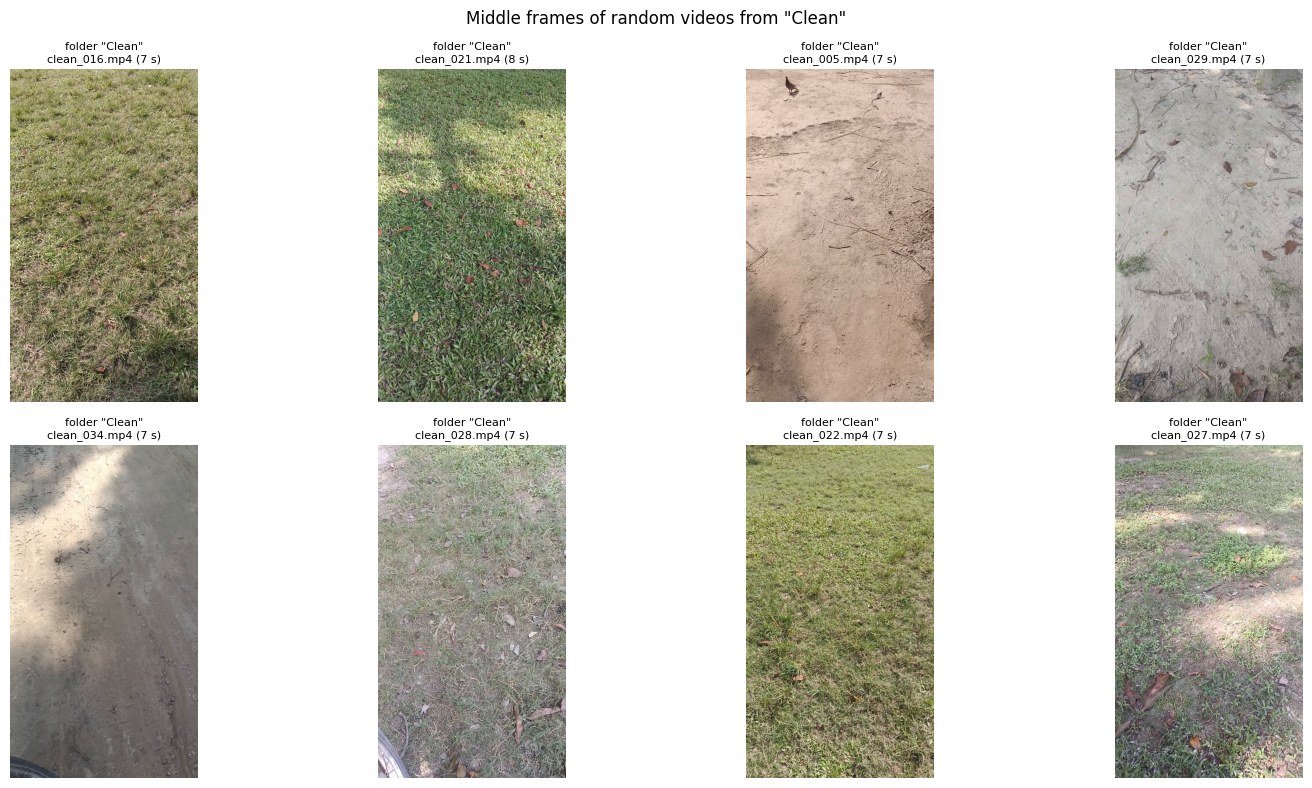

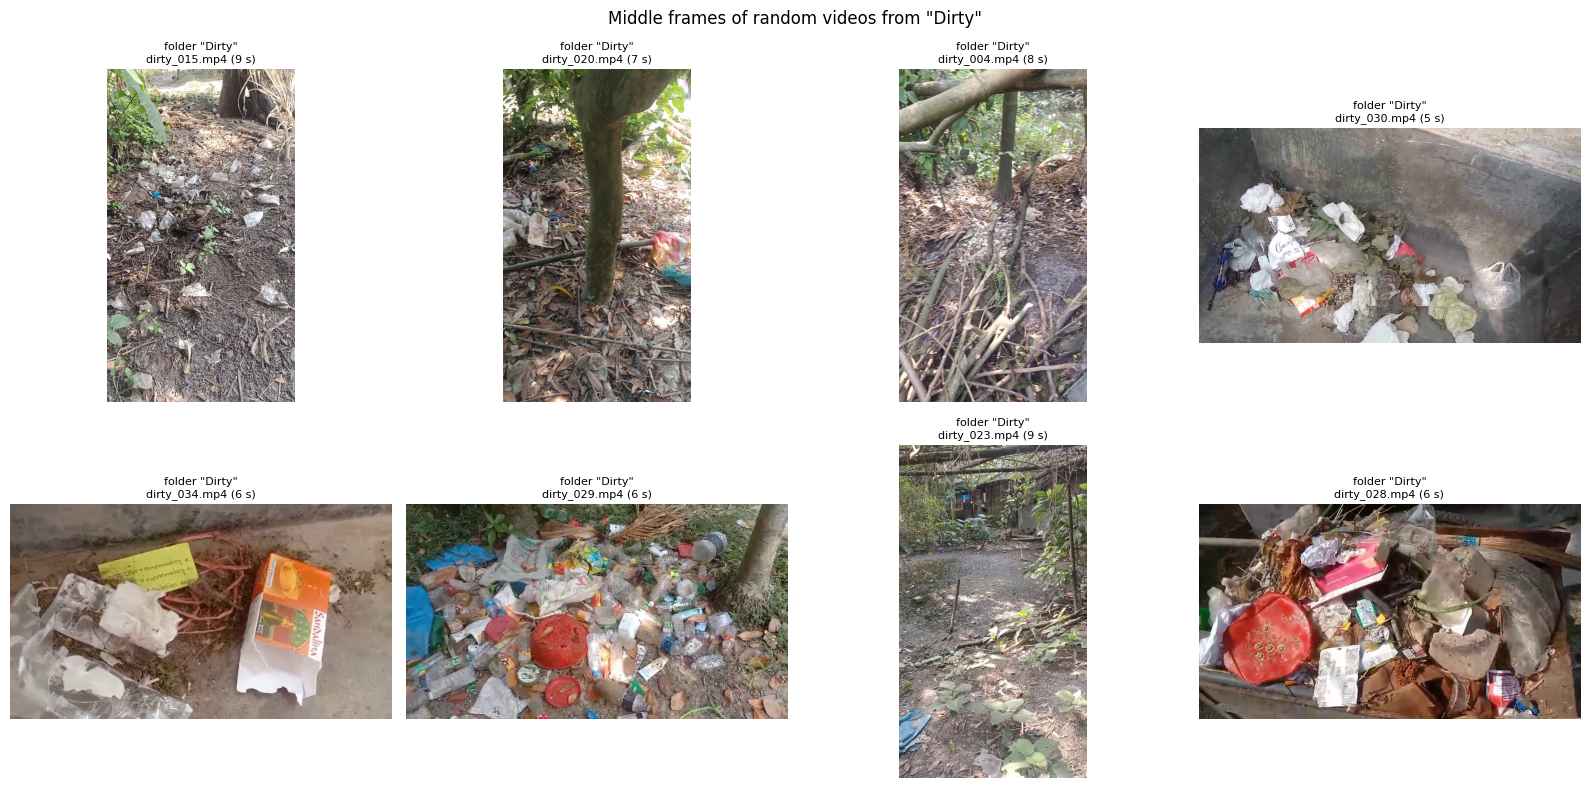

In [ ]:
def read_frame_at(path, frac=0.5):
    cap = cv2.VideoCapture(str(path)); n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT)); cap.set(cv2.CAP_PROP_POS_FRAMES, int(n * frac)); ok, bgr = cap.read(); cap.release()
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB) if ok else np.zeros((120, 160, 3), np.uint8)
for folder in VID.folder.unique():
    sub = VID[VID.folder == folder].sample(min(8, (VID.folder == folder).sum()), random_state=1); fig, axs = plt.subplots(2, 4, figsize=(16, 8)); axs = axs.ravel()
    for ax in axs: ax.axis('off')
    for ax, (_, r) in zip(axs, sub.iterrows()): ax.imshow(read_frame_at(r.path)); ax.set_title(f'folder "{folder}"\n{r["name"]} ({r.duration_s:.0f} s)', fontsize=8)
    plt.suptitle(f'Middle frames of random videos from "{folder}"'); plt.tight_layout(); savefig(f'samples_folder_{folder}'); plt.show()

### 1.3 Label check

Labels come from the **folder names**. The check below compares them with the file-name prefixes (`clean_...`, `dirty_...`). If the names say the opposite of the folders in both folders, the notebook stops and asks you to look at the images and decide (`SWAP_FOLDER_LABELS`), because a swapped labelling would silently make every table and example wrong.

In [ ]:
def name_prefix(fn): return re.sub(r'[\s_\-]*\d+$', '', Path(fn).stem.lower())
CLEAN_KW, DIRTY_KW = ('clean', 'tidy', 'neat'), ('dirt', 'garb', 'trash', 'waste', 'litter', 'dump', 'mess', 'rubbish', 'filth')
def kw_label(prefix):
    c, d = any(k in prefix for k in CLEAN_KW), any(k in prefix for k in DIRTY_KW)
    return 'Clean' if c and not d else 'Dirty' if d and not c else None
print('file-name prefixes per folder:'); print(VID.groupby('folder').name.apply(lambda s: Counter(name_prefix(x) for x in s).most_common(3)).to_string())
votes = {f: Counter(kw_label(name_prefix(x)) for x in VID[VID.folder == f].name) for f in VID.folder.unique()}
def implied(f):
    v = votes[f]; tot = v['Clean'] + v['Dirty']
    return None if tot < 0.8 * sum(v.values()) else ('Clean' if v['Clean'] > v['Dirty'] else 'Dirty')
imp = {f: implied(f) for f in votes}; own = {f: ('Clean' if f.lower().startswith('clean') else 'Dirty') for f in votes}
dis = [f for f in imp if imp[f] is not None and imp[f] != own[f]]
print('label implied by file names:', imp, '| label implied by folder names:', own)
if SWAP_FOLDER_LABELS is None:
    if len(dis) == len(imp) and all(v is not None for v in imp.values()):
        raise RuntimeError('The file names say the opposite of the folder names in BOTH folders. Look at the sample frames above and set '
                           'SWAP_FOLDER_LABELS = True (videos match the file names) or False (videos match the folder names), then re-run from the settings cell.')
    SWAP_FOLDER_LABELS = False; print('Decision: folder names are used as labels.')
else: print('Decision taken by you: SWAP_FOLDER_LABELS =', SWAP_FOLDER_LABELS)
VID['label'] = VID.folder_label.map(lambda v: 1 - v) if SWAP_FOLDER_LABELS else VID.folder_label
VID['class_name'] = VID.label.map(dict(enumerate(CLASS_NAMES)))
print('class counts:', VID.class_name.value_counts().to_dict())

file-name prefixes per folder:
folder
Clean    [(clean, 34)]
Dirty    [(dirty, 35)]
label implied by file names: {'Clean': 'Clean', 'Dirty': 'Dirty'} | label implied by folder names: {'Clean': 'Clean', 'Dirty': 'Dirty'}
Decision: folder names are used as labels.
class counts: {'Dirty': 35, 'Clean': 34}


### 1.4 Duplicates

Exact duplicate files (same bytes) are removed. Near-duplicate videos (for example the same clip exported twice) are looked for by comparing a difference hash of the first, middle and last frame.

In [ ]:
def dhash(img, n=8):
    g = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY); g = cv2.resize(g, (n + 1, n), interpolation=cv2.INTER_AREA); return (g[:, 1:] > g[:, :-1]).flatten()
VID = VID[~VID.md5.duplicated()].reset_index(drop=True)
HV = np.stack([np.concatenate([dhash(read_frame_at(p, f)) for f in (0.02, 0.5, 0.98)]) for p in tqdm(VID.path, desc='hashing', leave=False)])
ham = (HV[:, None, :] != HV[None, :, :]).sum(-1); iu = np.triu_indices(len(VID), 1)
close = [(VID.video_id[i], VID.video_id[j], int(ham[i, j])) for i, j in zip(*iu) if ham[i, j] <= 20]    # 3 x 64 bits; <= 20 differing bits in total
print('videos kept after removing exact duplicates:', len(VID), '| near-duplicate pairs (<= 20 of 192 hash bits differ):', len(close)); print(close[:8])

hashing:   0%|          | 0/69 [00:00<?, ?it/s]

videos kept after removing exact duplicates: 69 | near-duplicate pairs (<= 20 of 192 hash bits differ): 0
[]


### 1.5 Optional: your own metadata for the robustness analysis

The assignment asks about robustness to **lighting, camera movement and environment**. Section 11 measures these from the videos automatically (brightness, camera-motion estimate, blur ...). If you also want to use your own descriptions (for example `indoor/outdoor`, `lighting = bright/dim`, `camera = static/handheld/walking`), fill in the template CSV written by the next cell, save it as `Clean_Dirty_Video_Dataset/video_metadata.csv`, and re-run from here; extra columns are picked up automatically.

In [ ]:
META_CSV = ROOT / 'video_metadata.csv'
if META_CSV.exists():
    META = pd.read_csv(META_CSV).set_index('video_id'); print('video_metadata.csv found; columns:', list(META.columns))
else:
    META = None
    pd.DataFrame({'video_id': VID.video_id, 'environment': '', 'lighting': '', 'camera_motion': '', 'notes': ''}).to_csv(ROOT / 'video_metadata_template.csv', index=False)
    print('no video_metadata.csv found; a blank template was written to', ROOT / 'video_metadata_template.csv')

no video_metadata.csv found; a blank template was written to /content/drive/MyDrive/Clean_Dirty_Video_Dataset/video_metadata_template.csv


## 2. Preprocessing and frame-level feature extraction (Task 2)

For every video:

1. **Frame sampling at a fixed rate.** Frames are read sequentially and a frame is kept whenever its timestamp (frame index / frame rate) passes the next multiple of `1 / BASE_FPS` seconds (4 fps). The timestamp of every kept frame is stored (needed for the timestamp extension).
2. **Resize** each kept frame to 224 x 224 (the whole frame is squashed, nothing is cropped, because dirt can be anywhere in the picture) and **normalise** with the ImageNet mean and standard deviation. Phone rotation tags are applied by OpenCV automatically.
3. **Pretrained CNN backbone:** ResNet-50 (ImageNet weights, `resnet50.tv_in1k`), frozen, global-average-pooled to a **2048-dimensional feature vector per frame**.
4. A video becomes a **sequence of frame feature vectors** (`n_frames x 2048`) plus the frame timestamps and small thumbnails. These are cached in `features/` in Drive, so this step runs only once.

Why frozen features? With a few dozen videos, fine-tuning a CNN would overfit, and the assignment asks that all three recurrent models share the same visual features.

In [ ]:
BACKBONE = timm.create_model('resnet50.tv_in1k', pretrained=True, num_classes=0).to(DEVICE).eval()
CFG_BB = timm.data.resolve_data_config({}, model=BACKBONE); BB_MEAN = torch.tensor(CFG_BB['mean'], device=DEVICE).view(1, 3, 1, 1); BB_STD = torch.tensor(CFG_BB['std'], device=DEVICE).view(1, 3, 1, 1)
FEAT_DIM = BACKBONE.num_features; print('backbone: resnet50.tv_in1k | feature dimension:', FEAT_DIM, '| mean/std:', CFG_BB['mean'], CFG_BB['std'])

@torch.no_grad()
def backbone_features(frames_u8, bs=64):
    """frames_u8: (N, 224, 224, 3) uint8 RGB -> (N, 2048) float16 features."""
    out = []
    for i in range(0, len(frames_u8), bs):
        x = torch.from_numpy(frames_u8[i:i + bs]).to(DEVICE).permute(0, 3, 1, 2).float().div(255); x = (x - BB_MEAN) / BB_STD
        with torch.autocast('cuda', dtype=torch.float16): f = BACKBONE(x)
        out.append(f.float().cpu().numpy().astype(np.float16))
    return np.concatenate(out) if out else np.zeros((0, FEAT_DIM), np.float16)

def extract_video(path, base_fps=BASE_FPS, max_seconds=None):
    """Decode one video at `base_fps`, return features, timestamps, thumbnails and timing."""
    t0 = perf_counter(); cap = cv2.VideoCapture(str(path)); fps = cap.get(cv2.CAP_PROP_FPS) or 30.0
    frames, thumbs, times = [], [], []; idx, next_t, step = 0, 0.0, 1.0 / base_fps
    while True:
        if not cap.grab(): break
        t = idx / fps; idx += 1
        if max_seconds and t > max_seconds: break
        if t + 1e-6 >= next_t:
            ok, bgr = cap.retrieve()
            if not ok: continue
            rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB); h, w = rgb.shape[:2]; s = THUMB_LONG / max(h, w)
            frames.append(cv2.resize(rgb, (FRAME_SIZE, FRAME_SIZE), interpolation=cv2.INTER_AREA)); thumbs.append(cv2.resize(rgb, (round(w * s), round(h * s)), interpolation=cv2.INTER_AREA)); times.append(t)
            next_t += step
            while next_t <= t: next_t += step          # skip ahead if the video had a gap
    cap.release(); t_dec = perf_counter() - t0
    t1 = perf_counter(); feats = backbone_features(np.stack(frames)) if frames else np.zeros((0, FEAT_DIM), np.float16); torch.cuda.synchronize(); t_bb = perf_counter() - t1
    return dict(F=feats, t=np.array(times, np.float32), thumbs=np.stack(thumbs) if thumbs else np.zeros((0, 1, 1, 3), np.uint8), t_decode=t_dec, t_backbone=t_bb)

def cache_path(vid): return FEAT_DIR / (re.sub(r'[^A-Za-z0-9_.-]+', '_', vid) + f'_{BASE_FPS}fps_{FRAME_SIZE}.npz')
TIMING = []
for _, r in tqdm(VID.iterrows(), total=len(VID), desc='extracting features'):
    cp = cache_path(r.video_id)
    if cp.exists(): continue
    e = extract_video(r.path)
    if len(e['F']) == 0: print('!! no frames decoded from', r.video_id); continue
    np.savez_compressed(cp, F=e['F'], t=e['t'], thumbs=e['thumbs']); TIMING.append(dict(video_id=r.video_id, frames=len(e['F']), t_decode=e['t_decode'], t_backbone=e['t_backbone']))
if TIMING:
    TM = pd.DataFrame(TIMING); print(f'extracted {len(TM)} videos, {TM.frames.sum()} frames | decoding {1e3 * TM.t_decode.sum() / TM.frames.sum():.1f} ms/frame | backbone {1e3 * TM.t_backbone.sum() / TM.frames.sum():.1f} ms/frame')
    TM.to_csv(DIRS['tables'] / 'feature_extraction_timing.csv', index=False)
else: print('all features were already cached')

FT, TT, THUMBS, keep = [], [], [], []
for i, r in VID.iterrows():
    cp = cache_path(r.video_id)
    if not cp.exists(): continue
    z = np.load(cp); FT.append(torch.from_numpy(z['F'].astype(np.float32)).to(DEVICE)); TT.append(z['t']); THUMBS.append(z['thumbs']); keep.append(i)
VID = VID.loc[keep].reset_index(drop=True); Y = VID.label.values; N = len(VID)
VID['n_base_frames'] = [len(t) for t in TT]
print('videos with features:', N, '| frames per video at 4 fps: median', int(VID.n_base_frames.median()), 'min', int(VID.n_base_frames.min()), 'max', int(VID.n_base_frames.max()))
print('feature tensor example:', tuple(FT[0].shape), '| total frames:', int(VID.n_base_frames.sum()))

backbone: resnet50.tv_in1k | feature dimension: 2048 | mean/std: (0.485, 0.456, 0.406) (0.229, 0.224, 0.225)


extracting features:   0%|          | 0/69 [00:00<?, ?it/s]

all features were already cached
videos with features: 69 | frames per video at 4 fps: median 30 min 22 max 52
feature tensor example: (26, 2048) | total frames: 2139


### 2.1 Do the features separate the classes at all?

A quick look before any model is trained: the **mean feature vector of each video** projected to 2 dimensions with PCA. If clean and dirty videos form visibly different clouds, the frozen ResNet features carry class information.

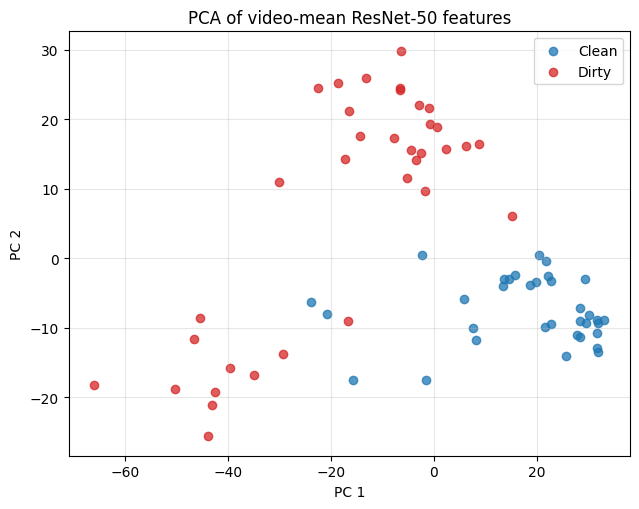

In [ ]:
from sklearn.decomposition import PCA
MEANF = np.stack([f.float().mean(0).cpu().numpy() for f in FT]); Z = PCA(2, random_state=0).fit_transform(StandardScaler().fit_transform(MEANF))
fig, ax = plt.subplots(figsize=(6.5, 5.2))
for c, col in ((0, 'tab:blue'), (1, 'tab:red')): ax.scatter(*Z[Y == c].T, c=col, label=CLASS_NAMES[c], alpha=.75)
ax.set_xlabel('PC 1'); ax.set_ylabel('PC 2'); ax.set_title('PCA of video-mean ResNet-50 features'); ax.legend(); ax.grid(alpha=.3); plt.tight_layout(); savefig('pca_video_features'); plt.show()

## 3. Train / validation / test split (Task 1)

### 3.1 Capture sessions and a leakage-free split

If the videos have creation times, a **new session starts whenever the gap to the previous video exceeds `SESSION_GAP_MIN` minutes**, and the split keeps every session in one set while balancing the classes (`StratifiedGroupKFold`). Several random draws are tried and the best-balanced one is kept. Without creation times, a stratified random split at video level is used and the notebook says so. The same machinery also produces the folds of the cross-validation in Section 8.

In [ ]:

# ============================================================
# STRATIFIED RANDOM TRAIN / VALIDATION / TEST SPLIT
# One video = one independent group
# ============================================================

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, StratifiedKFold
from collections import Counter

# ------------------------------------------------------------
# 1. Create independent video groups
# ------------------------------------------------------------

N = len(VID)
GROUPS = np.arange(N)
group_desc = 'stratified random split at video level'
VID['group'] = GROUPS

print(
    'Grouping:', group_desc,
    '| groups:', len(GROUPS),
    '| largest group: 1 video'
)

# Ensure labels are encoded as integers
Y = np.asarray(Y)

assert len(Y) == N, "Y and VID must contain the same number of videos."
assert N >= 20, "Too few videos for a reliable split."

class_counts = Counter(Y)
assert min(class_counts.values()) >= 3, (
    "Each class needs at least 3 videos for train/val/test splitting."
)

# ------------------------------------------------------------
# 2. Define stratified random split function
# ------------------------------------------------------------

def make_split(y, groups, seed, test_frac, val_frac):
    y = np.asarray(y)
    indices = np.arange(len(y))

    # First: separate test videos
    trainval_idx, test_idx = train_test_split(
        indices,
        test_size=test_frac,
        random_state=seed,
        stratify=y
    )

    # Second: separate validation videos from remaining videos
    relative_val_frac = val_frac / (1.0 - test_frac)

    train_idx, val_idx = train_test_split(
        trainval_idx,
        test_size=relative_val_frac,
        random_state=seed + 1,
        stratify=y[trainval_idx]
    )

    return train_idx, val_idx, test_idx

# ------------------------------------------------------------
# 3. Create splits
# ------------------------------------------------------------

TR, VA, TE = make_split(
    Y, GROUPS, SEED_SPLIT, TEST_FRAC, VAL_FRAC
)

VID['split'] = ''
VID.loc[TR, 'split'] = 'train'
VID.loc[VA, 'split'] = 'val'
VID.loc[TE, 'split'] = 'test'

# Verify that no video occurs in multiple splits
assert not (set(TR) & set(VA))
assert not (set(TR) & set(TE))
assert not (set(VA) & set(TE))
assert len(TR) + len(VA) + len(TE) == N

# ------------------------------------------------------------
# 4. Display split summary
# ------------------------------------------------------------

TAB = pd.crosstab(
    VID['split'], VID['class_name']
).reindex(['train', 'val', 'test'], fill_value=0)

TAB['total'] = TAB.sum(axis=1)
TAB['share %'] = (
    100 * TAB['total'] / TAB['total'].sum()
).round(1)

TAB['frames @4fps'] = [
    int(VID.loc[VID['split'] == s, 'n_base_frames'].sum())
    for s in TAB.index
]

print('\nDataset split summary:')
display(TAB)

# Save tables
TAB.to_csv(DIRS['tables'] / 'dataset_split_table.csv')

VID.drop(columns=['md5'], errors='ignore').to_csv(
    DIRS['tables'] / 'video_dataset_index.csv',
    index=False
)

# ------------------------------------------------------------
# 5. Report class distribution
# ------------------------------------------------------------

print('\nClass distribution per split:')
print(pd.crosstab(VID['split'], VID['class_name']))

print('\nVideos per split:')
print('Train:', len(TR))
print('Validation:', len(VA))
print('Test:', len(TE))

# ------------------------------------------------------------
# 6. Generate stratified random cross-validation folds
# ------------------------------------------------------------

def make_cv_folds(y, groups, k, seed, val_splits=3):
    y = np.asarray(y)
    indices = np.arange(len(y))
    class_counts = Counter(y)

    # Avoid requesting more folds than the smallest class supports
    k = min(k, min(class_counts.values()))

    if k < 2:
        raise ValueError(
            "At least 2 videos per class are needed for cross-validation."
        )

    folds = []

    outer_cv = StratifiedKFold(
        n_splits=k, shuffle=True, random_state=seed
    )

    for trainval_idx, test_idx in outer_cv.split(indices, y):
        y_trainval = y[trainval_idx]
        min_trainval_class = min(Counter(y_trainval).values())

        inner_k = min(val_splits, min_trainval_class)

        if inner_k < 2:
            raise ValueError(
                "Not enough videos per class for an inner validation split."
            )

        inner_cv = StratifiedKFold(
            n_splits=inner_k,
            shuffle=True,
            random_state=seed + len(folds) + 1
        )

        train_rel, val_rel = next(
            inner_cv.split(trainval_idx, y_trainval)
        )

        train_idx = trainval_idx[train_rel]
        val_idx = trainval_idx[val_rel]

        folds.append((train_idx, val_idx, test_idx))

    return folds

FOLDS = make_cv_folds(
    Y, GROUPS, CV_FOLDS, SEED_SPLIT
)

print(
    '\nCross-validation folds (test videos per fold):',
    [len(fold[2]) for fold in FOLDS]
)


Grouping: stratified random split at video level | groups: 69 | largest group: 1 video

Dataset split summary:


class_name,Clean,Dirty,total,share %,frames @4fps
split,,,,,
train,23,24,47,68.1,1455
val,6,5,11,15.9,372
test,5,6,11,15.9,312



Class distribution per split:
class_name  Clean  Dirty
split                   
test            5      6
train          23     24
val             6      5

Videos per split:
Train: 47
Validation: 11
Test: 11

Cross-validation folds (test videos per fold): [10, 10, 10, 10, 10, 10, 9]


## 4. The three recurrent video models (Task 3)

All three models are the **same network** except for the recurrent cell:

```
frame features (T x 2048) -> LayerNorm -> Dropout -> Linear(2048 -> 256) -> ReLU      [shared]
                          -> recurrent layer (hidden size 128)  <- nn.RNN | nn.LSTM | nn.GRU
                          -> last hidden state at the last real frame (padding is ignored)
                          -> Dropout -> Linear(128 -> 2)                               [shared]
```

| Cell | What it does | Weight matrices per layer |
|---|---|---|
| RNN (tanh) | $h_t = \tanh(W_x x_t + W_h h_{t-1} + b)$: a single state, no gates, so gradients vanish or explode over long sequences | 1 x (input and hidden weights) |
| LSTM | input, forget and output gates plus a separate **cell state** $c_t$ that can carry information almost unchanged over many steps | 4 x |
| GRU | update and reset gates, one state; fewer weights than the LSTM | 3 x |

The predicted label ("Clean" or "Dirty") is the video's **index**. For videos longer than one window the window probabilities are averaged (Section 5). The recurrent layers are unidirectional so that the models really process the sequence in time order.

In [ ]:
HID, PROJ, DROP = 128, 256, 0.3
class SeqClassifier(nn.Module):
    def __init__(self, cell, in_dim=FEAT_DIM, proj=PROJ, hidden=HID, drop=DROP, n_cls=2):
        super().__init__(); self.cell = cell
        self.proj = nn.Sequential(nn.LayerNorm(in_dim), nn.Dropout(drop), nn.Linear(in_dim, proj), nn.ReLU())
        self.rnn = {'rnn': lambda: nn.RNN(proj, hidden, batch_first=True, nonlinearity='tanh'), 'lstm': lambda: nn.LSTM(proj, hidden, batch_first=True),
                    'gru': lambda: nn.GRU(proj, hidden, batch_first=True)}[cell]()
        self.head = nn.Sequential(nn.Dropout(drop), nn.Linear(hidden, n_cls))
    def forward(self, x, lengths):
        packed = nn.utils.rnn.pack_padded_sequence(self.proj(x), lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, h = self.rnn(packed); last = h[0][-1] if self.cell == 'lstm' else h[-1]
        return self.head(last)

CELLS = ['rnn', 'lstm', 'gru']; CELL_LABEL = {'rnn': 'RNN', 'lstm': 'LSTM', 'gru': 'GRU'}
def n_params(m): return sum(p.numel() for p in m.parameters())
rows = []
for c in CELLS:
    m = SeqClassifier(c); rec = n_params(m.rnn); shared = n_params(m) - rec
    macs_step = {'rnn': HID * (PROJ + HID), 'lstm': 4 * HID * (PROJ + HID), 'gru': 3 * HID * (PROJ + HID)}[c]       # multiply-accumulates of the recurrent cell per time step
    rows.append(dict(model=CELL_LABEL[c], total_params=n_params(m), recurrent_params=rec, shared_params=shared, recurrent_MACs_per_step=macs_step,
                     recurrent_MACs_T16=macs_step * 16, ratio_recurrent_vs_RNN=round(rec / n_params(SeqClassifier('rnn').rnn), 2)))
PARAMS = pd.DataFrame(rows).set_index('model'); display(PARAMS); PARAMS.to_csv(DIRS['tables'] / 'parameters.csv')
with torch.no_grad(): print('forward check:', SeqClassifier('lstm')(torch.randn(3, 16, FEAT_DIM), torch.tensor([16, 9, 3])).shape)
print('The recurrent layer is a small part of every model; most parameters sit in the shared projection (2048 -> 256). The differences between models are therefore small in total size')
print('but exactly proportional to the number of gates in the recurrent layer (1 : 4 : 3 for RNN : LSTM : GRU).')

,total_params,recurrent_params,shared_params,recurrent_MACs_per_step,recurrent_MACs_T16,ratio_recurrent_vs_RNN
model,,,,,,
RNN,578306,49408,528898,49152,786432,1.0
LSTM,726530,197632,528898,196608,3145728,4.0
GRU,677122,148224,528898,147456,2359296,3.0


forward check: torch.Size([3, 2])
The recurrent layer is a small part of every model; most parameters sit in the shared projection (2048 -> 256). The differences between models are therefore small in total size
but exactly proportional to the number of gates in the recurrent layer (1 : 4 : 3 for RNN : LSTM : GRU).


## 5. Training and evaluation protocol (Task 4)

**Sampling and windows.** For a sampling rate `fps` (2 by default) the cached 4-fps features are subsampled with a stride of `4 / fps`. The model reads windows of `T` consecutive sampled frames (16 by default; 16 frames at 2 fps cover 8 s).

* **Training:** every epoch, each training video yields one random window (random start, random sampling phase, 10 % of the frames randomly dropped as augmentation). Videos shorter than `T` frames are zero-padded and the padding is skipped by the recurrent layer.
* **Testing:** the video is covered by consecutive windows (the last one right-aligned) at phase 0, and the window probabilities are **averaged**, so the prediction always uses the whole video.
* **Recipe (identical for the three models):** AdamW (learning rate 1e-3, weight decay 1e-2), cosine decay, batch size 8, label smoothing 0.05, gradient clipping 1.0, at most 80 epochs, dropout 0.3. After every epoch the model is scored on the **validation** videos; the best epoch (macro-F1, ties by validation loss) is kept and training stops after 15 epochs without improvement.
* **The test videos are never used** to choose an epoch, a hyperparameter or a threshold. The recipe is a sensible default, **not tuned** for any cell.

In [ ]:
CFG = dict(epochs=3 if QUICK_TEST else 80, patience=15, bs=8, lr=1e-3, wd=1e-2, smoothing=0.05, clip=1.0, frame_drop=0.1)
display(pd.DataFrame({'setting': list(CFG), 'value': list(CFG.values())}).set_index('setting').T)

def eval_windows(L, T):
    """(start, end) of the consecutive windows that cover a sequence of length L; the last window is right-aligned."""
    if L <= T: return [(0, L)]
    starts = list(range(0, L - T + 1, T))
    if starts[-1] + T < L: starts.append(L - T)
    return [(s, s + T) for s in starts]

def stride_of(fps): s = BASE_FPS / fps; assert abs(s - round(s)) < 1e-9, 'fps must divide BASE_FPS (or BASE_FPS / fps must be an integer)'; return int(round(s))

def make_batch(vlist, fps, T, rng):
    s = stride_of(fps); xs, ls = [], []
    for v in vlist:
        F_ = FT[v][int(rng.integers(0, s))::s]; L = F_.shape[0]
        if CFG['frame_drop'] > 0 and L > 4:
            kp = rng.random(L) > CFG['frame_drop']
            if kp.sum() >= 2: F_ = F_[torch.as_tensor(kp, device=F_.device)]; L = F_.shape[0]
        if L > T: a = int(rng.integers(0, L - T + 1)); F_ = F_[a:a + T]; L = T
        pad = torch.zeros(T, FEAT_DIM, device=DEVICE); pad[:L] = F_; xs.append(pad); ls.append(L)
    return torch.stack(xs), torch.tensor(ls)

@torch.no_grad()
def predict_videos(model, idxs, fps, T, mode='orig', seed=0, return_windows=False):
    """Video-level probabilities (n, 2): window probabilities averaged over the whole video. mode: 'orig' | 'shuffle' | 'reverse'."""
    model.eval(); s = stride_of(fps); rng = np.random.default_rng(seed); X, Ls, owner, spans = [], [], [], []
    for k, v in enumerate(idxs):
        F_ = FT[int(v)][0::s]; L = F_.shape[0]
        if mode == 'shuffle': F_ = F_[torch.as_tensor(rng.permutation(L), device=F_.device)]
        elif mode == 'reverse': F_ = torch.flip(F_, dims=[0])
        for a, b in eval_windows(L, T):
            pad = torch.zeros(T, FEAT_DIM, device=DEVICE); pad[:b - a] = F_[a:b]; X.append(pad); Ls.append(b - a); owner.append(k); spans.append((int(v), a, b, s))
    X, Lt, owner = torch.stack(X), torch.tensor(Ls), np.array(owner)
    P = torch.cat([model(X[i:i + 256], Lt[i:i + 256]).float().softmax(-1) for i in range(0, len(X), 256)]).cpu().numpy()
    out = np.stack([P[owner == k].mean(0) for k in range(len(idxs))])
    return (out, dict(P=P, owner=owner, spans=spans)) if return_windows else out

def macro_f1(y, p): return precision_recall_fscore_support(y, p.argmax(1), average='macro', zero_division=0)[2]
def nll(y, p): return float(-np.log(np.clip(p[np.arange(len(y)), y], 1e-8, 1)).mean())

def train_eval(cell, tr, va, te, fps=FPS, T=T_WIN, seed=42, epochs=None, keep_model=False):
    """Train one recurrent model on videos `tr`, select the epoch on `va`, return probabilities on `te`."""
    epochs = epochs or CFG['epochs']; seed_everything(seed); rng = np.random.default_rng(seed); model = SeqClassifier(cell).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=CFG['lr'], weight_decay=CFG['wd']); sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    crit = nn.CrossEntropyLoss(label_smoothing=CFG['smoothing']); best, best_state, bad, hist = (-1.0, 1e9), None, 0, []; t0 = perf_counter(); tr = np.array(tr)
    for ep in range(1, epochs + 1):
        model.train(); perm = rng.permutation(len(tr)); run, n = 0.0, 0
        for i in range(0, len(perm), CFG['bs']):
            vb = tr[perm[i:i + CFG['bs']]]
            if len(vb) < 2: continue
            x, ln = make_batch(vb, fps, T, rng); y = torch.as_tensor(Y[vb], device=DEVICE)
            loss = crit(model(x, ln).float(), y); opt.zero_grad(set_to_none=True); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), CFG['clip']); opt.step()
            run += loss.item() * len(vb); n += len(vb)
        sched.step(); pv = predict_videos(model, va, fps, T); f1 = macro_f1(Y[va], pv); lv = nll(Y[va], pv)
        hist.append(dict(epoch=ep, train_loss=run / max(n, 1), val_loss=lv, val_macro_f1=f1, val_acc=float((pv.argmax(1) == Y[va]).mean())))
        if (f1, -lv) > (best[0], -best[1]): best, bad, best_state = (f1, lv), 0, copy.deepcopy(model.state_dict()); hist[-1]['best'] = True
        else: bad += 1
        if bad >= CFG['patience']: break
    model.load_state_dict(best_state); res = dict(p_test=predict_videos(model, te, fps, T), hist=pd.DataFrame(hist), train_time_s=perf_counter() - t0,
                                                  best_epoch=int(pd.DataFrame(hist).query('best == True').epoch.max()), val_f1=best[0], state=best_state)
    if keep_model: res['model'] = model
    else: del model
    return res

setting,epochs,patience,bs,lr,wd,smoothing,clip,frame_drop
value,80.0,15.0,8.0,0.001,0.01,0.05,1.0,0.1


### 5.1 Metrics

Positive class = **Dirty**. Precision is the share of videos called dirty that are dirty, recall the share of dirty videos found; macro values average both classes. Intervals: Wilson 95 % interval for accuracy, bootstrap interval over videos for accuracy and F1.

In [ ]:
def wilson(k, n, z=1.96):
    if n == 0: return (np.nan, np.nan)
    p = k / n; d = 1 + z * z / n; c = (p + z * z / (2 * n)) / d; h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d; return (c - h, c + h)

def clf_metrics(y, p):
    pred = p.argmax(1); pr, rc, f1, _ = precision_recall_fscore_support(y, pred, labels=[0, 1], zero_division=0); mp, mr, mf, _ = precision_recall_fscore_support(y, pred, average='macro', zero_division=0)
    both = len(set(y)) > 1
    return dict(accuracy=accuracy_score(y, pred), precision=pr[1], recall=rc[1], f1=f1[1], macro_f1=mf, balanced_acc=balanced_accuracy_score(y, pred),
                auc=roc_auc_score(y, p[:, 1]) if both else np.nan, brier=brier_score_loss(y, p[:, 1]))

def bootstrap_ci(y, p, fn, n=2000, seed=0):
    rng = np.random.default_rng(seed); out = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        if len(set(y[i])) == 2: out.append(fn(y[i], p[i]))
    return tuple(np.percentile(out, [2.5, 97.5])) if out else (np.nan, np.nan)

KEYS = ['accuracy', 'precision', 'recall', 'f1', 'macro_f1', 'auc']
def fmt_ms(vals): return f'{np.mean(vals):.3f} ± {np.std(vals):.3f}'

## 6. Main experiment on the fixed split (Task 4)

Every recurrent model is trained with the same 5 seeds on the same training videos; the best epoch of each run is chosen on the validation videos, and the held-out test videos are scored once.

RNN   seed 42: best epoch  8 | val macro-F1 1.000 | test acc 1.000 F1 1.000 | 3 s
RNN   seed 43: best epoch  2 | val macro-F1 1.000 | test acc 1.000 F1 1.000 | 1 s
RNN   seed 44: best epoch 20 | val macro-F1 1.000 | test acc 1.000 F1 1.000 | 4 s
RNN   seed 45: best epoch  2 | val macro-F1 1.000 | test acc 1.000 F1 1.000 | 1 s
RNN   seed 46: best epoch  2 | val macro-F1 1.000 | test acc 1.000 F1 1.000 | 1 s
LSTM  seed 42: best epoch  2 | val macro-F1 1.000 | test acc 1.000 F1 1.000 | 1 s
LSTM  seed 43: best epoch  2 | val macro-F1 1.000 | test acc 1.000 F1 1.000 | 1 s
LSTM  seed 44: best epoch  2 | val macro-F1 1.000 | test acc 1.000 F1 1.000 | 1 s
LSTM  seed 45: best epoch 21 | val macro-F1 1.000 | test acc 1.000 F1 1.000 | 2 s
LSTM  seed 46: best epoch  3 | val macro-F1 1.000 | test acc 1.000 F1 1.000 | 1 s
GRU   seed 42: best epoch 11 | val macro-F1 1.000 | test acc 1.000 F1 1.000 | 1 s
GRU   seed 43: best epoch  2 | val macro-F1 1.000 | test acc 1.000 F1 1.000 | 1 s
GRU   seed 44: b

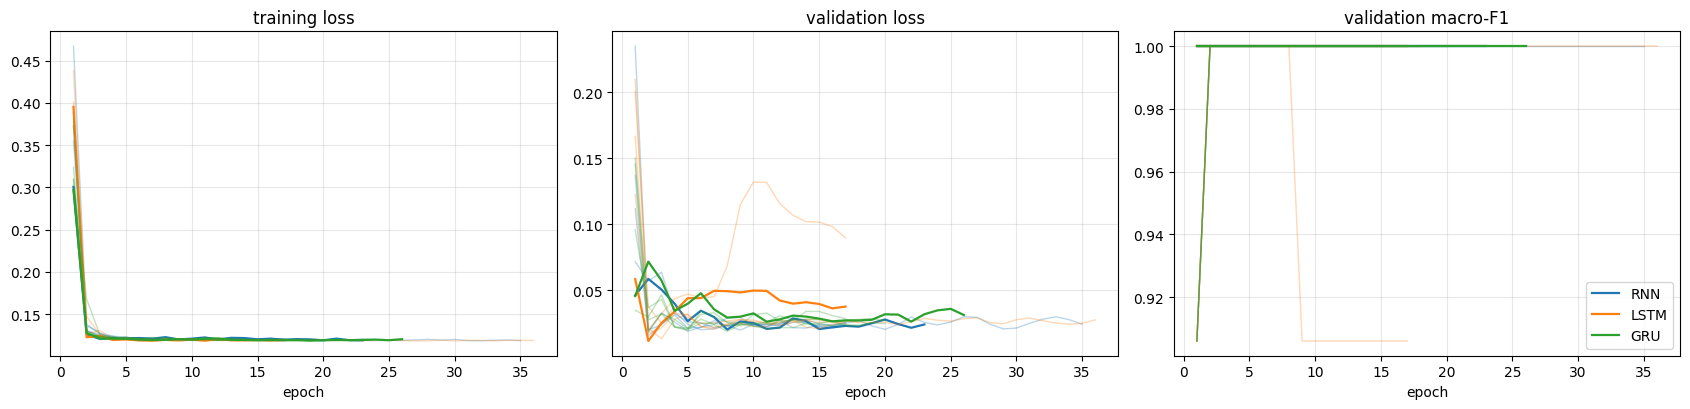

In [ ]:
MAIN = {}        # (cell, seed) -> result dict
for cell in CELLS:
    for seed in SEEDS:
        r = train_eval(cell, TR, VA, TE, FPS, T_WIN, seed); MAIN[(cell, seed)] = r
        r['hist'].to_csv(DIRS['models'] / f'history_{cell}_seed{seed}.csv', index=False); torch.save(r['state'], DIRS['models'] / f'{cell}_seed{seed}.pt')
        m = clf_metrics(Y[TE], r['p_test']); print(f"{CELL_LABEL[cell]:5s} seed {seed}: best epoch {r['best_epoch']:2d} | val macro-F1 {r['val_f1']:.3f} | test acc {m['accuracy']:.3f} F1 {m['f1']:.3f} | {r['train_time_s']:.0f} s")
fig, axs = plt.subplots(1, 3, figsize=(17, 4.2)); cols = {'rnn': 'tab:blue', 'lstm': 'tab:orange', 'gru': 'tab:green'}
for cell in CELLS:
    for seed in SEEDS:
        H = MAIN[(cell, seed)]['hist']; kw = dict(color=cols[cell], alpha=1 if seed == SEEDS[0] else .3, lw=1.6 if seed == SEEDS[0] else 1, label=CELL_LABEL[cell] if seed == SEEDS[0] else None)
        axs[0].plot(H.epoch, H.train_loss, **kw); axs[1].plot(H.epoch, H.val_loss, **kw); axs[2].plot(H.epoch, H.val_macro_f1, **kw)
for a, t in zip(axs, ['training loss', 'validation loss', 'validation macro-F1']): a.set_title(t); a.set_xlabel('epoch'); a.grid(alpha=.3)
axs[2].legend(); plt.tight_layout(); savefig('training_curves'); plt.show()

### 6.1 Test results (fixed split)

TEST set (11 videos), mean ± std over 5 training seeds; positive class = Dirty


,seeds,accuracy,precision,recall,f1,macro_f1,auc,mean_best_epoch,train_time_s
model,,,,,,,,,
RNN,5,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,6.8,1.797561
LSTM,5,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,6.0,0.997172
GRU,5,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,5.6,0.967399


confidence intervals, first seed (42)


,correct,wilson_95,boot_acc_95
model,,,
RNN,11/11,"[0.74, 1.00]","[1.00, 1.00]"
LSTM,11/11,"[0.74, 1.00]","[1.00, 1.00]"
GRU,11/11,"[0.74, 1.00]","[1.00, 1.00]"


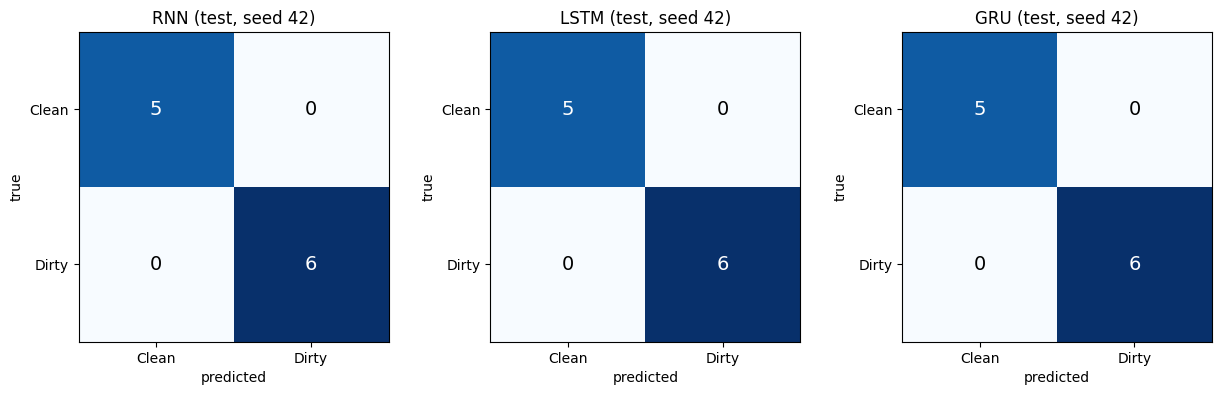

In [ ]:
rows = []
for cell in CELLS:
    ms = [clf_metrics(Y[TE], MAIN[(cell, s)]['p_test']) for s in SEEDS]
    rows.append(dict(model=CELL_LABEL[cell], seeds=len(SEEDS), **{k: fmt_ms([m[k] for m in ms]) for k in KEYS},
                     mean_best_epoch=np.mean([MAIN[(cell, s)]['best_epoch'] for s in SEEDS]), train_time_s=np.mean([MAIN[(cell, s)]['train_time_s'] for s in SEEDS])))
RES_MAIN = pd.DataFrame(rows).set_index('model'); print(f'TEST set ({len(TE)} videos), mean ± std over {len(SEEDS)} training seeds; positive class = Dirty'); display(RES_MAIN); RES_MAIN.to_csv(DIRS['tables'] / 'results_fixed_split.csv')
ci = []
for cell in CELLS:
    p0 = MAIN[(cell, SEEDS[0])]['p_test']; k = int((p0.argmax(1) == Y[TE]).sum()); lo, hi = wilson(k, len(TE))
    ba = bootstrap_ci(Y[TE], p0, lambda a, b: accuracy_score(a, b.argmax(1))); ci.append(dict(model=CELL_LABEL[cell], correct=f'{k}/{len(TE)}', wilson_95=f'[{lo:.2f}, {hi:.2f}]', boot_acc_95=f'[{ba[0]:.2f}, {ba[1]:.2f}]'))
print(f'confidence intervals, first seed ({SEEDS[0]})'); display(pd.DataFrame(ci).set_index('model'))
fig, axs = plt.subplots(1, 3, figsize=(12.5, 3.9))
for ax, cell in zip(axs, CELLS):
    cm = confusion_matrix(Y[TE], MAIN[(cell, SEEDS[0])]['p_test'].argmax(1), labels=[0, 1]); ax.imshow(cm, cmap='Blues'); ax.set_xticks([0, 1]); ax.set_yticks([0, 1]); ax.set_xticklabels(CLASS_NAMES); ax.set_yticklabels(CLASS_NAMES)
    ax.set_xlabel('predicted'); ax.set_ylabel('true'); ax.set_title(f'{CELL_LABEL[cell]} (test, seed {SEEDS[0]})')
    for (a, b), v in np.ndenumerate(cm): ax.text(b, a, v, ha='center', va='center', color='white' if v > cm.max() * .55 else 'black', fontsize=14)
plt.tight_layout(); savefig('confusion_matrices_fixed_split'); plt.show()

## 7. Does temporal information help? (Task 5)

Recurrent models can only be said to "learn temporal information" if the **order** of the frames matters or if they beat methods that ignore order. Three non-temporal baselines use exactly the same frame features and the same training/validation/test videos:

| Baseline | How it classifies a video |
|---|---|
| **Single frame** | Logistic regression trained on individual frames (each frame gets its video's label); the video is classified from **one random frame**. Reported as the expected value over 200 random draws per video. |
| **Frame average** | The same frame classifier, but the frame probabilities of the whole video are **averaged** (order is ignored). |
| **Mean feature** | Logistic regression on the **average feature vector** of the video (order and frame-level variation are ignored). |

And two order tests on the trained recurrent models: the **test frames are shuffled** (5 random orders, averaged) or **reversed**. If the accuracy does not change, the model is using the frames as a bag, not as a sequence.

In [ ]:
FN = [f.cpu().numpy() for f in FT]      # numpy copies of the features (for scikit-learn)
def frame_arrays(vids, fps):
    s = stride_of(fps); X = np.concatenate([FN[int(v)][0::s] for v in vids]); y = np.concatenate([np.full(len(FN[int(v)][0::s]), Y[int(v)]) for v in vids]); return X, y
def frame_probs(clf, sc, v, fps): return clf.predict_proba(sc.transform(FN[int(v)][0::stride_of(fps)]))[:, 1]
def two_col(p1): p1 = np.asarray(p1); return np.stack([1 - p1, p1], 1)

def fit_frame_lr(tr, va, fps, Cs=(0.001, 0.01, 0.1, 1.0)):
    X, y = frame_arrays(tr, fps); sc = StandardScaler().fit(X); best = None; Xs = sc.transform(X)
    for C in Cs:
        clf = LogisticRegression(C=C, max_iter=500, class_weight='balanced').fit(Xs, y)
        pv = two_col([frame_probs(clf, sc, v, fps).mean() for v in va]); key = (macro_f1(Y[va], pv), -nll(Y[va], pv))
        if best is None or key > best[0]: best = (key, clf, C)
    return sc, best[1], best[2]

def fit_meanfeat_lr(tr, va, fps, Cs=(0.001, 0.01, 0.1, 1.0)):
    mf = lambda vids: np.stack([FN[int(v)][0::stride_of(fps)].mean(0) for v in vids]); sc = StandardScaler().fit(mf(tr)); best = None
    for C in Cs:
        clf = LogisticRegression(C=C, max_iter=1000, class_weight='balanced').fit(sc.transform(mf(tr)), Y[tr]); pv = clf.predict_proba(sc.transform(mf(va)))
        key = (macro_f1(Y[va], pv), -nll(Y[va], pv))
        if best is None or key > best[0]: best = (key, clf, C)
    return (lambda vids: best[1].predict_proba(sc.transform(mf(vids)))), best[2]

def baselines_for(tr, va, te, fps):
    sc, clf, C = fit_frame_lr(tr, va, fps); pf = {int(v): frame_probs(clf, sc, v, fps) for v in te}
    predict_mf, C2 = fit_meanfeat_lr(tr, va, fps)
    return dict(frame_mean=two_col([pf[int(v)].mean() for v in te]), mean_feat=predict_mf(te), PF=pf, clf=clf, sc=sc)

def single_frame_expected(PF, vids, draws=200, seed=0):
    rng = np.random.default_rng(seed); vids = list(vids); y = Y[vids]; ms = []
    for _ in range(draws): ms.append(clf_metrics(y, two_col([PF[int(v)][rng.integers(0, len(PF[int(v)]))] for v in vids])))
    return {k: float(np.nanmean([m[k] for m in ms])) for k in ms[0]}

def load_model(cell, state):
    m = SeqClassifier(cell).to(DEVICE); m.load_state_dict(state); return m.eval()

N_SHUF = 5
def order_probs(model, idxs, fps, T):
    return dict(orig=predict_videos(model, idxs, fps, T), shuffle=[predict_videos(model, idxs, fps, T, 'shuffle', seed=100 + j) for j in range(N_SHUF)], reverse=predict_videos(model, idxs, fps, T, 'reverse'))

In [ ]:
BL = baselines_for(TR, VA, TE, FPS); SINGLE = single_frame_expected(BL['PF'], TE)
rows = [dict(model='Single frame (expected, 200 draws)', **{k: f'{SINGLE[k]:.3f}' for k in KEYS}),
        dict(model='Frame average (logistic regression)', **{k: f'{clf_metrics(Y[TE], BL["frame_mean"])[k]:.3f}' for k in KEYS}),
        dict(model='Mean feature (logistic regression)', **{k: f'{clf_metrics(Y[TE], BL["mean_feat"])[k]:.3f}' for k in KEYS})]
for cell in CELLS: rows.append(dict(model=f'{CELL_LABEL[cell]} (mean ± std, {len(SEEDS)} seeds)', **{k: RES_MAIN.loc[CELL_LABEL[cell], k] for k in KEYS}))
TEMP_MAIN = pd.DataFrame(rows).set_index('model'); print(f'Fixed split, test set ({len(TE)} videos): temporal models vs. models that ignore order'); display(TEMP_MAIN); TEMP_MAIN.to_csv(DIRS['tables'] / 'temporal_vs_frame_fixed_split.csv')

rows = []
for cell in CELLS:
    acc = {'orig': [], 'shuffle': [], 'reverse': []}; f1 = {'orig': [], 'shuffle': [], 'reverse': []}
    for s in SEEDS:
        op = order_probs(load_model(cell, MAIN[(cell, s)]['state']), TE, FPS, T_WIN)
        for md in acc:
            ps = op[md] if md == 'shuffle' else [op[md]]; ms = [clf_metrics(Y[TE], p) for p in ps]
            acc[md].append(np.mean([m['accuracy'] for m in ms])); f1[md].append(np.mean([m['macro_f1'] for m in ms]))
    rows.append(dict(model=CELL_LABEL[cell], acc_original=np.mean(acc['orig']), acc_shuffled=np.mean(acc['shuffle']), acc_reversed=np.mean(acc['reverse']),
                     macroF1_original=np.mean(f1['orig']), macroF1_shuffled=np.mean(f1['shuffle']), macroF1_reversed=np.mean(f1['reverse']), drop_when_shuffled=np.mean(acc['orig']) - np.mean(acc['shuffle'])))
ORDER_MAIN = pd.DataFrame(rows).set_index('model'); print('Frame-order test on the fixed split (mean over seeds):'); display(ORDER_MAIN.round(3)); ORDER_MAIN.round(4).to_csv(DIRS['tables'] / 'order_test_fixed_split.csv')
print('A drop close to 0 means the model does not use the order of the frames. With a small test set, Section 8 repeats this on every video.')

Fixed split, test set (11 videos): temporal models vs. models that ignore order


,accuracy,precision,recall,f1,macro_f1,auc
model,,,,,,
"Single frame (expected, 200 draws)",1.000,1.000,1.000,1.000,1.000,1.000
Frame average (logistic regression),1.000,1.000,1.000,1.000,1.000,1.000
Mean feature (logistic regression),1.000,1.000,1.000,1.000,1.000,1.000
"RNN (mean ± std, 5 seeds)",1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000
"LSTM (mean ± std, 5 seeds)",1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000
"GRU (mean ± std, 5 seeds)",1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000


Frame-order test on the fixed split (mean over seeds):


,acc_original,acc_shuffled,acc_reversed,macroF1_original,macroF1_shuffled,macroF1_reversed,drop_when_shuffled
model,,,,,,,
RNN,1.0,0.996,1.0,1.0,0.996,1.0,0.004
LSTM,1.0,1.000,1.0,1.0,1.000,1.0,0.000
GRU,1.0,1.000,1.0,1.0,1.000,1.0,0.000


A drop close to 0 means the model does not use the order of the frames. With a small test set, Section 8 repeats this on every video.


## 8. Cross-validation: a more reliable estimate (Tasks 4 and 5)

A test set of a dozen videos can only give a rough picture. **Grouped, stratified K-fold cross-validation** repeats the whole procedure (train on the training part, choose the epoch on a validation part, predict the held-out fold) `K` times so that **every video receives an out-of-fold prediction** from a model that never saw it or its capture session. Pooled over all videos this gives much narrower intervals and also supplies enough data for the robustness and error analyses of Section 11. The fixed split above remains the main result required by the assignment; the cross-validation is its robustness check. One model per fold and cell (seed = split seed + fold number).


cross-validation (fps 2, T 16, 7 folds) finished in 0.0 min
7-fold grouped cross-validation, out-of-fold predictions pooled over all 69 videos


,accuracy,precision,recall,f1,macro_f1,auc,wilson_95_acc,acc_std_over_folds
model,,,,,,,,
Single frame (expected),0.985,1.0,0.971,0.985,0.985,0.999,,
Frame average,0.986,1.0,0.971,0.986,0.986,1.000,"[0.92, 1.00]",0.039
Mean feature,0.986,1.0,0.971,0.986,0.986,0.999,"[0.92, 1.00]",0.039
RNN,1.000,1.0,1.000,1.000,1.000,1.000,"[0.95, 1.00]",0.0
LSTM,1.000,1.0,1.000,1.000,1.000,1.000,"[0.95, 1.00]",0.0
GRU,1.000,1.0,1.000,1.000,1.000,1.000,"[0.95, 1.00]",0.0


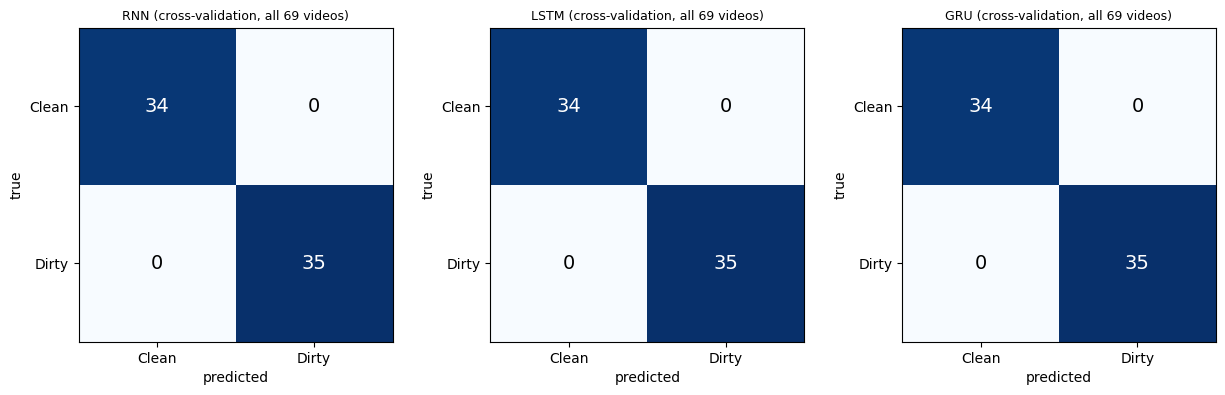

In [ ]:
import pickle
def cv_cached(fps, T, orders=False, baselines=True):
    f = DIRS['predictions'] / f'cv_fps{fps}_T{T}_o{int(orders)}_b{int(baselines)}_K{CV_FOLDS}.pkl'
    if f.exists() and not QUICK_TEST:
        return pickle.load(open(f, 'rb'))
    OOF = {c: np.zeros((N, 2)) for c in CELLS}; ORD = {c: dict(shuffle=[np.zeros((N, 2)) for _ in range(N_SHUF)], reverse=np.zeros((N, 2))) for c in CELLS}
    BASE = dict(frame_mean=np.zeros((N, 2)), mean_feat=np.zeros((N, 2))); PF = {}; fold_of = np.zeros(N, int); best_ep = {c: [] for c in CELLS}
    for k, (tr, va, te) in enumerate(FOLDS):
        fold_of[te] = k
        for c in CELLS:
            r = train_eval(c, tr, va, te, fps, T, SEED_SPLIT + k, keep_model=orders); OOF[c][te] = r['p_test']; best_ep[c].append(r['best_epoch'])
            if orders:
                op = order_probs(r['model'], te, fps, T)
                for j in range(N_SHUF): ORD[c]['shuffle'][j][te] = op['shuffle'][j]
                ORD[c]['reverse'][te] = op['reverse']; del r['model']
        if baselines:
            b = baselines_for(tr, va, te, fps); BASE['frame_mean'][te] = b['frame_mean']; BASE['mean_feat'][te] = b['mean_feat']; PF.update(b['PF'])
        print(f'  fold {k + 1}/{len(FOLDS)} done (fps {fps}, T {T})', end='\r')
    res = dict(OOF=OOF, ORD=ORD, BASE=BASE, PF=PF, fold_of=fold_of, best_epoch=best_ep)
    if not QUICK_TEST: pickle.dump(res, open(f, 'wb'))
    return res

t0 = perf_counter(); CV = cv_cached(FPS, T_WIN, orders=True, baselines=True); print(f'\ncross-validation (fps {FPS}, T {T_WIN}, {CV_FOLDS} folds) finished in {(perf_counter() - t0) / 60:.1f} min')
rows = []; pools = {}
for name, p in [(f'Single frame (expected)', None), ('Frame average', CV['BASE']['frame_mean']), ('Mean feature', CV['BASE']['mean_feat'])] + [(CELL_LABEL[c], CV['OOF'][c]) for c in CELLS]:
    if p is None: m = single_frame_expected(CV['PF'], range(N)); k = m['accuracy'] * N; ci_ = ('', '')
    else:
        m = clf_metrics(Y, p); k = int((p.argmax(1) == Y).sum()); lo, hi = wilson(k, N); ci_ = (f'[{lo:.2f}, {hi:.2f}]', '')
        pools[name] = p
    fold_acc = [accuracy_score(Y[CV['fold_of'] == f], p[CV['fold_of'] == f].argmax(1)) for f in range(CV_FOLDS)] if p is not None else [np.nan]
    rows.append(dict(model=name, **{k_: round(m[k_], 3) for k_ in KEYS}, wilson_95_acc=ci_[0], acc_std_over_folds=round(float(np.std(fold_acc)), 3) if p is not None else ''))
RES_CV = pd.DataFrame(rows).set_index('model'); print(f'{CV_FOLDS}-fold grouped cross-validation, out-of-fold predictions pooled over all {N} videos'); display(RES_CV); RES_CV.to_csv(DIRS['tables'] / 'results_cross_validation.csv')

fig, axs = plt.subplots(1, 3, figsize=(12.5, 3.9))
for ax, c in zip(axs, CELLS):
    cm = confusion_matrix(Y, CV['OOF'][c].argmax(1), labels=[0, 1]); ax.imshow(cm, cmap='Blues'); ax.set_xticks([0, 1]); ax.set_yticks([0, 1]); ax.set_xticklabels(CLASS_NAMES); ax.set_yticklabels(CLASS_NAMES)
    ax.set_xlabel('predicted'); ax.set_ylabel('true'); ax.set_title(f'{CELL_LABEL[c]} (cross-validation, all {N} videos)', fontsize=9)
    for (a, b), v in np.ndenumerate(cm): ax.text(b, a, v, ha='center', va='center', color='white' if v > cm.max() * .55 else 'black', fontsize=14)
plt.tight_layout(); savefig('confusion_matrices_cv'); plt.show()

### 8.1 Are the differences between the models significant? Frame-order test on all videos

McNemar's exact test compares two classifiers on the videos where they disagree. **A large p-value does not show the models are equal, only that the data cannot separate them.** The order test below repeats Section 7 on all out-of-fold predictions.

In [ ]:
names = list(pools); corr = {n: pools[n].argmax(1) == Y for n in names}
MN = pd.DataFrame(index=names, columns=names, dtype=object)
for a in names:
    for b in names:
        if a == b: MN.loc[a, b] = '-'; continue
        n01 = int((corr[a] & ~corr[b]).sum()); n10 = int((~corr[a] & corr[b]).sum()); pv = stats.binomtest(min(n01, n10), n01 + n10, 0.5).pvalue if n01 + n10 else 1.0
        MN.loc[a, b] = f'{n01}/{n10} (p={pv:.2f})'
print('cell = (row right & column wrong) / (row wrong & column right), exact two-sided p-value, out-of-fold predictions of all videos'); display(MN); MN.to_csv(DIRS['tables'] / 'mcnemar_cv.csv')
rows = []
for c in CELLS:
    sh = [clf_metrics(Y, p) for p in CV['ORD'][c]['shuffle']]; o = clf_metrics(Y, CV['OOF'][c]); rv = clf_metrics(Y, CV['ORD'][c]['reverse'])
    rows.append(dict(model=CELL_LABEL[c], acc_original=o['accuracy'], acc_shuffled=np.mean([m['accuracy'] for m in sh]), acc_reversed=rv['accuracy'],
                     macroF1_original=o['macro_f1'], macroF1_shuffled=np.mean([m['macro_f1'] for m in sh]), macroF1_reversed=rv['macro_f1'], drop_when_shuffled=o['accuracy'] - np.mean([m['accuracy'] for m in sh])))
ORDER_CV = pd.DataFrame(rows).set_index('model'); print(f'Frame-order test, out-of-fold predictions of all {N} videos'); display(ORDER_CV.round(3)); ORDER_CV.round(4).to_csv(DIRS['tables'] / 'order_test_cv.csv')

cell = (row right & column wrong) / (row wrong & column right), exact two-sided p-value, out-of-fold predictions of all videos


,Frame average,Mean feature,RNN,LSTM,GRU
Frame average,-,0/0 (p=1.00),0/1 (p=1.00),0/1 (p=1.00),0/1 (p=1.00)
Mean feature,0/0 (p=1.00),-,0/1 (p=1.00),0/1 (p=1.00),0/1 (p=1.00)
RNN,1/0 (p=1.00),1/0 (p=1.00),-,0/0 (p=1.00),0/0 (p=1.00)
LSTM,1/0 (p=1.00),1/0 (p=1.00),0/0 (p=1.00),-,0/0 (p=1.00)
GRU,1/0 (p=1.00),1/0 (p=1.00),0/0 (p=1.00),0/0 (p=1.00),-


Frame-order test, out-of-fold predictions of all 69 videos


,acc_original,acc_shuffled,acc_reversed,macroF1_original,macroF1_shuffled,macroF1_reversed,drop_when_shuffled
model,,,,,,,
RNN,1.0,1.0,1.0,1.0,1.0,1.0,0.0
LSTM,1.0,1.0,1.0,1.0,1.0,1.0,0.0
GRU,1.0,1.0,1.0,1.0,1.0,1.0,0.0


## 9. Effect of sampling rate and sequence length (Task 4)

Both studies use the cross-validation of Section 8 (one model per fold and cell) and report the pooled out-of-fold accuracy and macro-F1.

* **Sampling rate** (`fps` in 0.5, 1, 2, 4) with a **fixed window of 16 frames**: a higher rate gives more frames per second but each window covers less time (16 frames cover 32 s, 16 s, 8 s and 4 s).
* **Sequence length** (`T` frames per window) at 2 fps: short windows see little of the video but the whole video is covered by averaging windows; long windows give the recurrent cell a long memory task. Videos shorter than `T` frames are zero-padded, so once `T` exceeds the typical video length (in frames) the results stop changing.

The frame-average baseline is added to the sampling-rate plot (it depends on the rate but not on `T`).


Effect of sampling rate: pooled out-of-fold macro-F1


fps,0.5,1.0,2.0,4.0
model,,,,
Frame average,0.986,0.986,0.986,0.986
GRU,1.000,1.000,1.000,1.000
LSTM,1.000,1.000,1.000,1.000
RNN,1.000,1.000,1.000,1.000



Effect of sequence length: pooled out-of-fold macro-F1


T,2,4,8,16,32,64
model,,,,,,
Frame average,NaN,NaN,NaN,0.986,NaN,NaN
GRU,1.000,1.0,0.971,1.000,1.0,1.0
LSTM,0.985,1.0,1.000,1.000,1.0,1.0
RNN,0.985,1.0,1.000,1.000,1.0,1.0


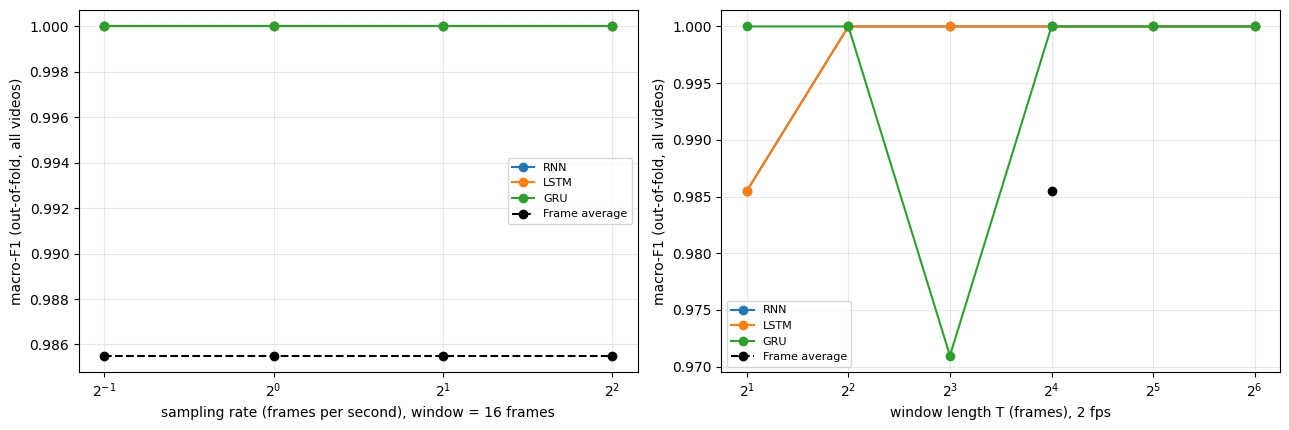

In [ ]:
def study_row(res, fps, T, kind):
    rows = []
    for c in CELLS: m = clf_metrics(Y, res['OOF'][c]); rows.append(dict(study=kind, model=CELL_LABEL[c], fps=fps, T=T, accuracy=m['accuracy'], macro_f1=m['macro_f1'], f1_dirty=m['f1']))
    if 'BASE' in res and res['BASE']['frame_mean'].any(): m = clf_metrics(Y, res['BASE']['frame_mean']); rows.append(dict(study=kind, model='Frame average', fps=fps, T=T, accuracy=m['accuracy'], macro_f1=m['macro_f1'], f1_dirty=m['f1']))
    return rows
STUDY = []
for f in FPS_LIST:
    res = CV if (f, T_WIN) == (FPS, T_WIN) else cv_cached(f, T_WIN, orders=False, baselines=True); STUDY += study_row(res, f, T_WIN, 'sampling rate')
for T in T_LIST:
    res = CV if (FPS, T) == (FPS, T_WIN) else cv_cached(FPS, T, orders=False, baselines=False); STUDY += study_row(res, FPS, T, 'sequence length')
STUDY = pd.DataFrame(STUDY); STUDY.to_csv(DIRS['tables'] / 'study_rate_and_length.csv', index=False)
for kind, col in (('sampling rate', 'fps'), ('sequence length', 'T')):
    print(f'\nEffect of {kind}: pooled out-of-fold macro-F1'); display(STUDY[STUDY.study == kind].pivot(index='model', columns=col, values='macro_f1').round(3))
fig, axs = plt.subplots(1, 2, figsize=(13, 4.4)); cols = {'RNN': 'tab:blue', 'LSTM': 'tab:orange', 'GRU': 'tab:green', 'Frame average': 'k'}
for ax, (kind, col, xl) in zip(axs, (('sampling rate', 'fps', 'sampling rate (frames per second), window = 16 frames'), ('sequence length', 'T', 'window length T (frames), 2 fps'))):
    for mname in ['RNN', 'LSTM', 'GRU', 'Frame average']:
        d = STUDY[(STUDY.study == kind) & (STUDY.model == mname)].sort_values(col)
        if len(d): ax.plot(d[col], d.macro_f1, 'o-', color=cols[mname], label=mname, ls='--' if mname == 'Frame average' else '-')
    ax.set_xscale('log', base=2); ax.set_xlabel(xl); ax.set_ylabel('macro-F1 (out-of-fold, all videos)'); ax.grid(alpha=.3); ax.legend(fontsize=8)
plt.tight_layout(); savefig('study_rate_and_length'); plt.show()

## 10. Computational complexity and inference time (Tasks 4 and 5)

* **Parameters:** Section 4 (total, recurrent and shared parts) and the analytic multiply-accumulates of the recurrent cell.
* **Inference time of the recurrent model** for one window of `T` frames, batch size 1: the network forward pass on already extracted features, on the GPU and on the CPU. 20 warm-up runs, then 3 rounds of 100 runs; the median of the round medians is reported together with the spread, because Colab timings can drift. The weights are irrelevant for timing, so untrained models are used.
* **Shared cost of indexing a video:** decoding the frames and running the ResNet-50 backbone, measured on a few of your videos. It is identical for the three models.
* **Training time** per run (Section 6).

GPU latency (ms) for T frames,8,16,32,64
model,,,,
GRU,0.806,0.906,1.104,1.471
LSTM,0.831,0.923,1.119,1.465
RNN,0.796,0.918,1.080,1.426


CPU latency (ms) for T frames,8,16,32,64
model,,,,
GRU,1.045,1.556,2.307,3.977
LSTM,1.090,1.649,2.498,4.061
RNN,0.830,1.192,1.554,2.497


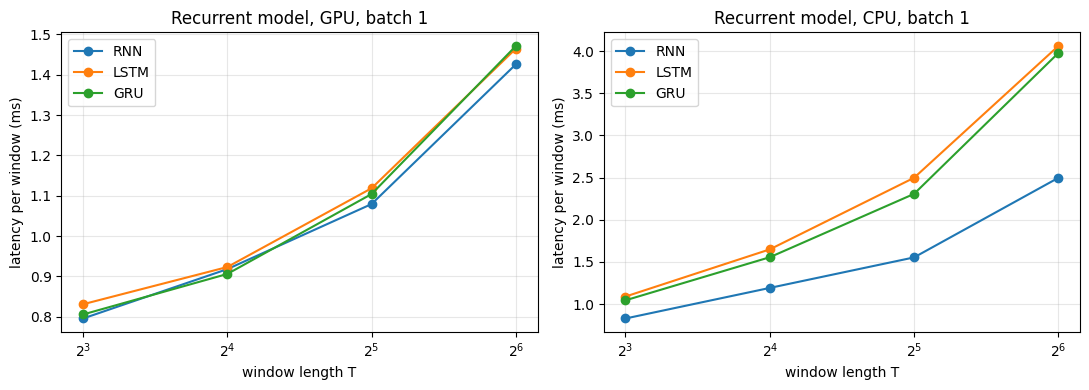

,video,duration_s,frames,decode_s,backbone_s
0,Dirty/dirty_030.mp4,5.44,22,0.40,0.88
1,Dirty/dirty_001.mp4,8.71,35,3.47,0.12
2,Dirty/dirty_024.mp4,9.01,36,3.70,0.11
3,Dirty/dirty_033.mp4,5.87,24,0.41,0.11


median video: 30 frames at 4 fps -> about 1 window(s) of 16 frames at 2 fps
indexing one video = decoding 1.99 s + ResNet-50 features 0.30 s (same for all models) + recurrent model about 0.9 ms (differs by cell)


,total_params,recurrent_params,recurrent_MACs_T16,gpu_ms_T16,cpu_ms_T16,train_time_s_per_run,cv_accuracy,cv_macro_f1
model,,,,,,,,
RNN,578306,49408,786432,0.918,1.192,1.798,1.0,1.0
LSTM,726530,197632,3145728,0.923,1.649,0.997,1.0,1.0
GRU,677122,148224,2359296,0.906,1.556,0.967,1.0,1.0


In [ ]:
@torch.no_grad()
def bench_head(cell, T, device, rounds=3, n=100, warm=20):
    m = SeqClassifier(cell).to(device).eval(); x = torch.randn(1, T, FEAT_DIM, device=device); ln = torch.tensor([T]); meds = []
    for _ in range(warm): m(x, ln)
    for _ in range(rounds):
        ts = []
        for _ in range(n):
            if device == 'cuda': torch.cuda.synchronize()
            t0 = perf_counter(); m(x, ln)
            if device == 'cuda': torch.cuda.synchronize()
            ts.append((perf_counter() - t0) * 1e3)
        meds.append(float(np.median(ts)))
    return float(np.median(meds)), min(meds), max(meds)

LAT = []
for c in CELLS:
    for T in (8, 16, 32, 64):
        g, glo, ghi = bench_head(c, T, 'cuda'); cp, clo, chi = bench_head(c, T, 'cpu', n=40, warm=5)
        LAT.append(dict(model=CELL_LABEL[c], T=T, gpu_ms=g, gpu_spread=f'{glo:.2f}-{ghi:.2f}', cpu_ms=cp, cpu_spread=f'{clo:.2f}-{chi:.2f}'))
LAT = pd.DataFrame(LAT); display(LAT.pivot(index='model', columns='T', values='gpu_ms').round(3).rename_axis(columns='GPU latency (ms) for T frames'))
display(LAT.pivot(index='model', columns='T', values='cpu_ms').round(3).rename_axis(columns='CPU latency (ms) for T frames')); LAT.round(4).to_csv(DIRS['tables'] / 'inference_time_head.csv', index=False)
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for ax, col, ttl in zip(axs, ('gpu_ms', 'cpu_ms'), ('GPU', 'CPU')):
    for c in CELLS: d = LAT[LAT.model == CELL_LABEL[c]]; ax.plot(d['T'], d[col], 'o-', label=CELL_LABEL[c], color=cols[CELL_LABEL[c]])
    ax.set_xscale('log', base=2); ax.set_xlabel('window length T'); ax.set_ylabel('latency per window (ms)'); ax.set_title(f'Recurrent model, {ttl}, batch 1'); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); savefig('inference_time_head'); plt.show()

# shared cost: decode + backbone, measured on a few videos (the cached features are not used here)
sample = VID.sample(min(4, N), random_state=0); tm = []
for _, r in sample.iterrows(): e = extract_video(r.path); tm.append(dict(video=r.video_id, duration_s=r.duration_s, frames=len(e['F']), decode_s=e['t_decode'], backbone_s=e['t_backbone']))
TM2 = pd.DataFrame(tm); display(TM2.round(2)); win_per_video = int(np.ceil(VID.n_base_frames.median() / stride_of(FPS) / T_WIN))
head_ms = float(LAT[(LAT['T'] == 16)].set_index('model').gpu_ms.mean()) * win_per_video
print(f'median video: {int(VID.n_base_frames.median())} frames at 4 fps -> about {win_per_video} window(s) of {T_WIN} frames at {FPS} fps')
print(f'indexing one video = decoding {TM2.decode_s.mean():.2f} s + ResNet-50 features {TM2.backbone_s.mean():.2f} s (same for all models) + recurrent model about {head_ms:.1f} ms (differs by cell)')
EFF = PARAMS[['total_params', 'recurrent_params', 'recurrent_MACs_T16']].copy()
EFF['gpu_ms_T16'] = LAT[LAT['T'] == 16].set_index('model').gpu_ms; EFF['cpu_ms_T16'] = LAT[LAT['T'] == 16].set_index('model').cpu_ms
EFF['train_time_s_per_run'] = [np.mean([MAIN[(c, s)]['train_time_s'] for s in SEEDS]) for c in CELLS]; EFF['cv_accuracy'] = [RES_CV.loc[CELL_LABEL[c], 'accuracy'] for c in CELLS]; EFF['cv_macro_f1'] = [RES_CV.loc[CELL_LABEL[c], 'macro_f1'] for c in CELLS]
display(EFF.round(3)); EFF.round(4).to_csv(DIRS['tables'] / 'comparative_performance_table.csv')

## 11. Robustness and error analysis (Task 5)

### 11.1 Measuring lighting, camera movement and environment

Whether a video was filmed in dim light, with a shaky camera, or in a cluttered place is not recorded, so the notebook **measures** it from the stored frames of every video:

| Property | Measure |
|---|---|
| **Lighting level** | mean brightness of the frames |
| **Lighting change** | standard deviation of the frame brightness over time |
| **Image quality** | sharpness (variance of the Laplacian, low = blurry) |
| **Camera movement** | mean dense optical-flow magnitude between consecutive frames (Farnebäck), as a fraction of the frame width |
| **Scene change** | mean absolute difference between consecutive frames |
| **Environment / clutter** | share of edge pixels; colourfulness |
| **Duration** | seconds |

Each property is split into three equal-sized bins; the table shows the **error rate per bin** using the out-of-fold predictions of **all videos** (Section 8), so each bin holds about a third of the dataset. Any columns of your own `video_metadata.csv` (for example `lighting`, `camera_motion`, `environment`) are analysed in the same way.

video descriptors:   0%|          | 0/69 [00:00<?, ?it/s]

Error rate of the recurrent models (mean over RNN, LSTM, GRU) by property bin; out-of-fold predictions, all videos


,error_low,error_medium,error_high,spearman_rho,p_value,RNN_low/high,LSTM_low/high,GRU_low/high
property,,,,,,,,
brightness,0.0,0.0,0.0,NaN,NaN,0.00/0.00,0.00/0.00,0.00/0.00
brightness_change,0.0,0.0,0.0,NaN,NaN,0.00/0.00,0.00/0.00,0.00/0.00
sharpness,0.0,0.0,0.0,NaN,NaN,0.00/0.00,0.00/0.00,0.00/0.00
camera_motion,0.0,0.0,0.0,NaN,NaN,0.00/0.00,0.00/0.00,0.00/0.00
scene_change,0.0,0.0,0.0,NaN,NaN,0.00/0.00,0.00/0.00,0.00/0.00
edge_density,0.0,0.0,0.0,NaN,NaN,0.00/0.00,0.00/0.00,0.00/0.00
colourfulness,0.0,0.0,0.0,NaN,NaN,0.00/0.00,0.00/0.00,0.00/0.00
duration_s,0.0,0.0,0.0,NaN,NaN,0.00/0.00,0.00/0.00,0.00/0.00


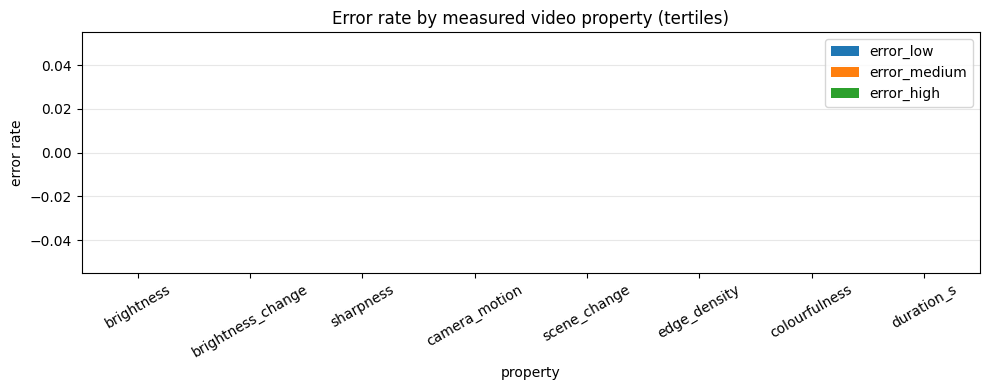

error rate by true class:
       RNN  LSTM  GRU
Clean  0.0   0.0  0.0
Dirty  0.0   0.0  0.0


In [ ]:
def video_descriptors(thumbs, t):
    g = [cv2.cvtColor(a, cv2.COLOR_RGB2GRAY) for a in thumbs]; hsv = [cv2.cvtColor(a, cv2.COLOR_RGB2HSV) for a in thumbs]
    br = np.array([x.mean() / 255 for x in g]); sharp = np.array([cv2.Laplacian(x, cv2.CV_64F).var() for x in g])
    W = thumbs.shape[2]; mot, diff = [], []
    for a, b in zip(g[:-1], g[1:]):
        fl = cv2.calcOpticalFlowFarneback(a, b, None, 0.5, 2, 15, 2, 5, 1.1, 0); mot.append(np.sqrt(fl[..., 0] ** 2 + fl[..., 1] ** 2).mean() / W); diff.append(np.abs(a.astype(float) - b.astype(float)).mean() / 255)
    rgb = thumbs[len(thumbs) // 2].astype(float); rg, yb = rgb[..., 0] - rgb[..., 1], 0.5 * (rgb[..., 0] + rgb[..., 1]) - rgb[..., 2]
    return dict(brightness=br.mean(), brightness_change=br.std(), sharpness=sharp.mean(), camera_motion=float(np.mean(mot)) if mot else 0.0, scene_change=float(np.mean(diff)) if diff else 0.0,
                edge_density=float(np.mean([(cv2.Canny(x, 100, 200) > 0).mean() for x in g])), colourfulness=math.sqrt(rg.std() ** 2 + yb.std() ** 2) + 0.3 * math.sqrt(rg.mean() ** 2 + yb.mean() ** 2),
                duration_s=float(t[-1] - t[0]) if len(t) > 1 else 0.0)
DESC = pd.DataFrame([video_descriptors(THUMBS[i], TT[i]) for i in tqdm(range(N), desc='video descriptors', leave=False)]); DESC.insert(0, 'video_id', VID.video_id.values)
DESC.to_csv(DIRS['tables'] / 'video_descriptors.csv', index=False)
ERR = pd.DataFrame({CELL_LABEL[c]: (CV['OOF'][c].argmax(1) != Y).astype(int) for c in CELLS}); ERR['Frame average'] = (CV['BASE']['frame_mean'].argmax(1) != Y).astype(int)
ERR['rec_mean'] = ERR[[CELL_LABEL[c] for c in CELLS]].mean(1); ERR['n_rec_wrong'] = ERR[[CELL_LABEL[c] for c in CELLS]].sum(1)
props = ['brightness', 'brightness_change', 'sharpness', 'camera_motion', 'scene_change', 'edge_density', 'colourfulness', 'duration_s']; rows = []
for p in props:
    b = pd.qcut(DESC[p].rank(method='first'), 3, labels=['low', 'medium', 'high']); e = ERR.groupby(b, observed=True).rec_mean.mean(); rho, pv = stats.spearmanr(DESC[p], ERR.rec_mean)
    rows.append(dict(property=p, error_low=e.get('low'), error_medium=e.get('medium'), error_high=e.get('high'), spearman_rho=rho, p_value=pv, **{f'{CELL_LABEL[c]}_low/high': f"{ERR.loc[b == 'low', CELL_LABEL[c]].mean():.2f}/{ERR.loc[b == 'high', CELL_LABEL[c]].mean():.2f}" for c in CELLS}))
FACT = pd.DataFrame(rows).set_index('property'); print('Error rate of the recurrent models (mean over RNN, LSTM, GRU) by property bin; out-of-fold predictions, all videos'); display(FACT.round(3)); FACT.round(4).to_csv(DIRS['tables'] / 'robustness_by_property.csv')
fig, ax = plt.subplots(figsize=(10, 4)); FACT[['error_low', 'error_medium', 'error_high']].plot.bar(ax=ax, rot=30); ax.set_ylabel('error rate'); ax.set_title('Error rate by measured video property (tertiles)'); ax.grid(axis='y', alpha=.3); plt.tight_layout(); savefig('robustness_by_property'); plt.show()
print('error rate by true class:'); print(pd.DataFrame({CELL_LABEL[c]: pd.Series(ERR[CELL_LABEL[c]].values).groupby(Y).mean().rename({0: 'Clean', 1: 'Dirty'}) for c in CELLS}).round(3).to_string())
if META is not None:
    for col in [c for c in META.columns if c != 'notes' and META[c].astype(str).str.len().gt(0).any()]:
        g = ERR.assign(cat=VID.video_id.map(META[col]).fillna('?').values).groupby('cat').agg(videos=('rec_mean', 'size'), error_rate=('rec_mean', 'mean')); print(f'\nerror rate by your metadata column "{col}":'); display(g.round(3))

### 11.2 Misclassified videos, and where temporal modelling helps or hurts

For each recurrent model the misclassified videos are listed, and the storyboards of the videos that **most models get wrong** are shown (eight evenly spaced frames, with the model probabilities of "Dirty"). The last table counts the videos on which the recurrent models and the frame-average baseline disagree: if the temporal models are right where the frame average is wrong, that is evidence that the sequence helped for those videos.

In [ ]:
WR = pd.DataFrame({'video_id': VID.video_id, 'true': [CLASS_NAMES[v] for v in Y], **{CELL_LABEL[c]: CV['OOF'][c][:, 1] for c in CELLS}, 'Frame average': CV['BASE']['frame_mean'][:, 1], 'n_rec_wrong': ERR.n_rec_wrong})
for c in CELLS:
    bad = WR[ERR[CELL_LABEL[c]] == 1][['video_id', 'true', CELL_LABEL[c]]].rename(columns={CELL_LABEL[c]: 'P(Dirty)'}); print(f'{CELL_LABEL[c]}: {len(bad)} of {N} videos misclassified'); display(bad.round(3))
WR.round(3).to_csv(DIRS['tables'] / 'out_of_fold_probabilities.csv', index=False)
hard = WR[WR.n_rec_wrong >= 2].sort_values('n_rec_wrong', ascending=False).head(6)
for i in hard.index:
    th = THUMBS[i]; sel = np.linspace(0, len(th) - 1, 8).astype(int); fig, axs = plt.subplots(1, 8, figsize=(18, 2.7))
    for ax, k in zip(axs, sel): ax.imshow(th[k]); ax.axis('off'); ax.set_title(f'{TT[i][k]:.1f}s', fontsize=7)
    plt.suptitle(f"{VID.video_id[i]} | true {WR.true[i]} | P(Dirty): " + ', '.join(f"{CELL_LABEL[c]} {CV['OOF'][c][i, 1]:.2f}" for c in CELLS) + f" | frame avg {CV['BASE']['frame_mean'][i, 1]:.2f}", fontsize=9, y=1.08)
    plt.tight_layout(); savefig(f'hard_video_{i}'); plt.show()
if len(hard) == 0: print('no video is misclassified by two or more recurrent models')
allrec_right = (ERR.n_rec_wrong == 0); allrec_wrong = (ERR.n_rec_wrong == len(CELLS)); fr_wrong = ERR['Frame average'] == 1
TMP = pd.DataFrame({'videos': [int((allrec_right & fr_wrong).sum()), int((allrec_wrong & ~fr_wrong).sum()), int((allrec_right & ~fr_wrong).sum()), int((allrec_wrong & fr_wrong).sum()), int(N - (allrec_right | allrec_wrong).sum())]},
                   index=['all 3 recurrent models right, frame average wrong (sequence helps)', 'all 3 recurrent models wrong, frame average right (sequence hurts)', 'all right', 'all wrong', 'recurrent models disagree among themselves'])
display(TMP); TMP.to_csv(DIRS['tables'] / 'temporal_vs_frame_disagreements.csv')

RNN: 0 of 69 videos misclassified


,video_id,true,P(Dirty)


LSTM: 0 of 69 videos misclassified


,video_id,true,P(Dirty)


GRU: 0 of 69 videos misclassified


,video_id,true,P(Dirty)


no video is misclassified by two or more recurrent models


,videos
"all 3 recurrent models right, frame average wrong (sequence helps)",1
"all 3 recurrent models wrong, frame average right (sequence hurts)",0
all right,68
all wrong,0
recurrent models disagree among themselves,0


## 12. Video indexing and retrieval (Task 6)

### 12.1 Assigning an index to every video

* **Index label** = the predicted class (Clean or Dirty) of the **index model** for the whole video. The default index model is the recurrent cell with the best mean **validation** macro-F1 on the fixed split (never chosen on test results); the interface also lets you pick RNN, LSTM, GRU or the frame-average baseline.
* Each model's probability is the **average over the 5 seeds** of the fixed-split models.
* **Important:** videos from the training split were seen by the models, so their labels are optimistic. The index therefore stores the **split** of each video and, for an honest view, the **out-of-fold probability** from the cross-validation. Quality statements about the index must use validation/test or out-of-fold predictions only.

In [ ]:
@torch.no_grad()
def predict_seq(model, F_full, t_full, fps, T):
    """One video given as feature tensor (n, 2048) at 4 fps and timestamps. Returns video probability, window P(Dirty), window centres and spans (seconds)."""
    s = stride_of(fps); F_ = F_full[0::s]; ts = np.asarray(t_full)[0::s]; wins = eval_windows(len(F_), T); X = torch.zeros(len(wins), T, FEAT_DIM, device=DEVICE); Ls = []
    for k, (a, b) in enumerate(wins): X[k, :b - a] = F_[a:b]; Ls.append(b - a)
    P = model.eval()(X, torch.tensor(Ls)).float().softmax(-1).cpu().numpy(); centres = [float(ts[(a + b - 1) // 2]) for a, b in wins]; spans = [(float(ts[a]), float(ts[b - 1] + 1 / fps)) for a, b in wins]
    return P.mean(0), P[:, 1], centres, spans

ENS = {c: [load_model(c, MAIN[(c, s)]['state']) for s in SEEDS] for c in CELLS}
def ensemble_probs(F_full, t_full, fps=FPS, T=T_WIN):
    out = {}
    for c in CELLS:
        r = [predict_seq(m, F_full, t_full, fps, T) for m in ENS[c]]; out[c] = dict(p=np.mean([x[0] for x in r], 0), win=np.mean([x[1] for x in r], 0), centres=r[0][2], spans=r[0][3])
    return out
VAL_F1 = {c: np.mean([MAIN[(c, s)]['val_f1'] for s in SEEDS]) for c in CELLS}; INDEX_CELL = max(VAL_F1, key=VAL_F1.get)
print('validation macro-F1 (mean over seeds):', {CELL_LABEL[c]: round(v, 3) for c, v in VAL_F1.items()}, '-> default index model:', CELL_LABEL[INDEX_CELL])

# frame-level classifier for timelines (trained on the training videos of the fixed split)
FRAME_SC, FRAME_CLF, FRAME_C = fit_frame_lr(TR, VA, FPS)
ALL_PROBS = [ensemble_probs(FT[i], TT[i]) for i in tqdm(range(N), desc='indexing videos', leave=False)]
FRAME_P = [FRAME_CLF.predict_proba(FRAME_SC.transform(FN[i][0::stride_of(FPS)]))[:, 1] for i in range(N)]
INDEX = VID[['video_id', 'split', 'duration_s', 'path']].copy(); INDEX['true_label'] = [CLASS_NAMES[v] for v in Y]
for c in CELLS: INDEX[f'p_{c}'] = [ALL_PROBS[i][c]['p'][1] for i in range(N)]; INDEX[f'p_{c}_oof'] = CV['OOF'][c][:, 1]
INDEX['p_frame'] = [FRAME_P[i].mean() for i in range(N)]; INDEX['p_frame_oof'] = CV['BASE']['frame_mean'][:, 1]
INDEX['index_label'] = np.where(INDEX[f'p_{INDEX_CELL}'] >= 0.5, 'Dirty', 'Clean'); INDEX['index_confidence'] = np.where(INDEX.index_label == 'Dirty', INDEX[f'p_{INDEX_CELL}'], 1 - INDEX[f'p_{INDEX_CELL}'])
INDEX['index_label_oof'] = np.where(INDEX[f'p_{INDEX_CELL}_oof'] >= 0.5, 'Dirty', 'Clean')
INDEX.drop(columns=['path']).round(4).to_csv(DIRS['tables'] / 'video_index.csv', index=False); INDEX.drop(columns=['path']).round(4).to_json(DIRS['tables'] / 'video_index.json', orient='records', indent=1)
print('index written. Agreement with the true label, by split (training videos are optimistic):')
display(INDEX.groupby('split').apply(lambda d: pd.Series(dict(videos=len(d), index_correct=(d.index_label == d.true_label).mean(), out_of_fold_correct=(d.index_label_oof == d.true_label).mean()))).round(3))

validation macro-F1 (mean over seeds): {'RNN': np.float64(1.0), 'LSTM': np.float64(1.0), 'GRU': np.float64(1.0)} -> default index model: RNN


indexing videos:   0%|          | 0/69 [00:00<?, ?it/s]

index written. Agreement with the true label, by split (training videos are optimistic):


,videos,index_correct,out_of_fold_correct
split,,,
test,11.0,1.0,1.0
train,47.0,1.0,1.0
val,11.0,1.0,1.0


### 12.2 Optional extension: where do dirty places appear? (timestamps)

The assignment asks to **distinguish classifying a whole video from locating dirty places in time**. The labels here are per video, so there is **no ground truth for timestamps** and the extension below can only be shown, not scored (unless you annotate some videos, see below).

Two time-resolved outputs are produced for every video:

* **Frame-level score:** the frame classifier of Section 7 (trained with the video label on every frame) gives P(Dirty) for each sampled frame (every 0.5 s at 2 fps). This is a *weak* signal: in a dirty video, frames showing a clean corner also carry the label "dirty".
* **Window-level score:** the recurrent models' probability for each window of 16 frames (a coarse, 8-second resolution).

Dirty **segments** are obtained from the smoothed frame scores (moving average of 3 frames, threshold 0.5, gaps up to 1 s merged, segments shorter than 1 s dropped).

**Optional evaluation.** If you note the dirty intervals of a few videos in `Clean_Dirty_Video_Dataset/dirty_segments.csv` (columns `video_id,start_s,end_s`), the next cells report frame-level precision, recall and F1 of the detected segments against your intervals.

Share of each video flagged as dirty (a weak proxy; no timestamp ground truth). Held-out videos (validation + test):


,count,mean,std,min,25%,50%,75%,max
true,,,,,,,,
Clean,11.0,0.000,0.000,0.000,0.000,0.000,0.0,0.0
Dirty,11.0,0.941,0.123,0.575,0.961,0.968,1.0,1.0


no dirty_segments.csv found: timestamps are shown but not scored.


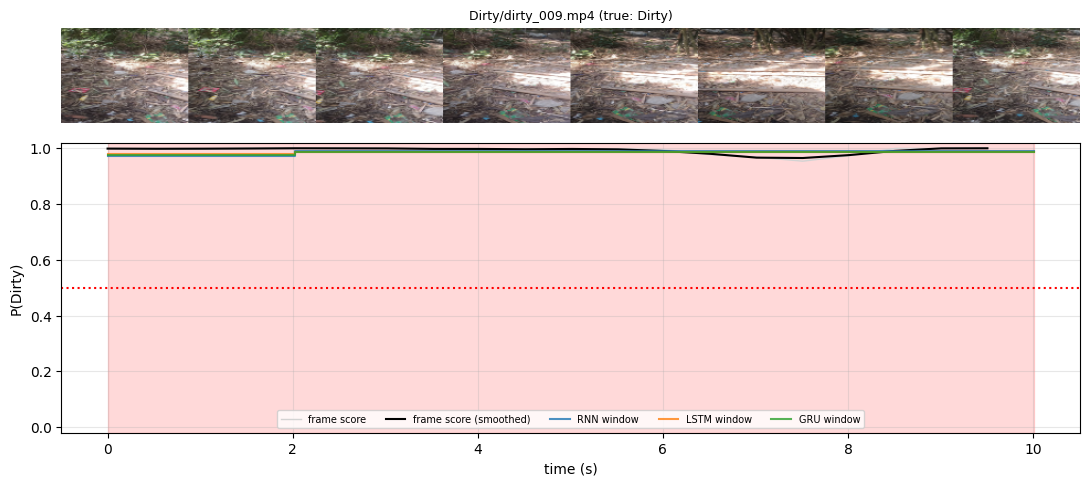

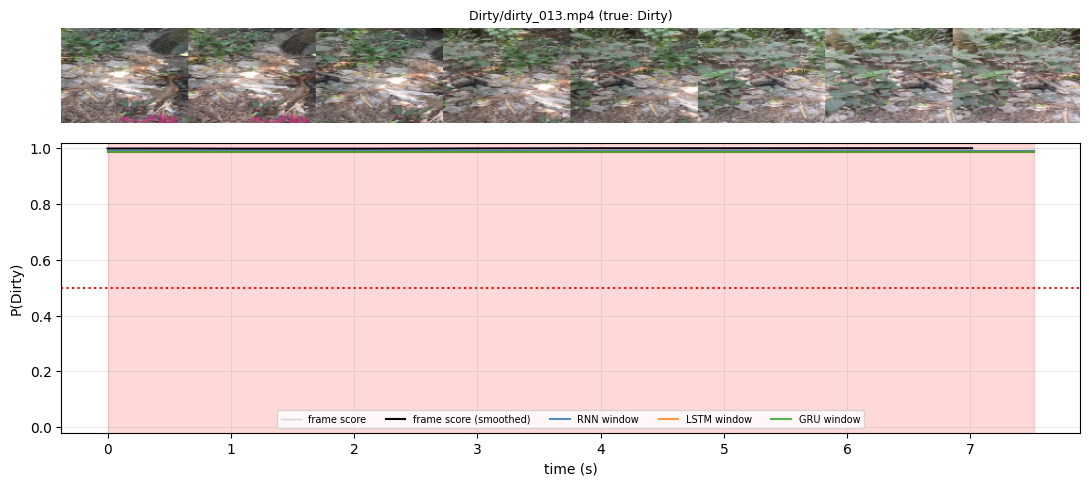

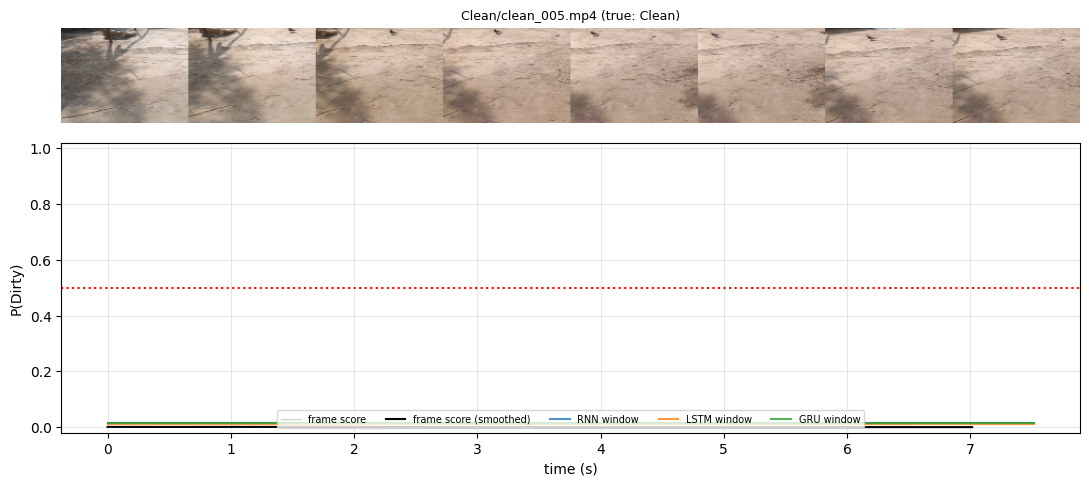

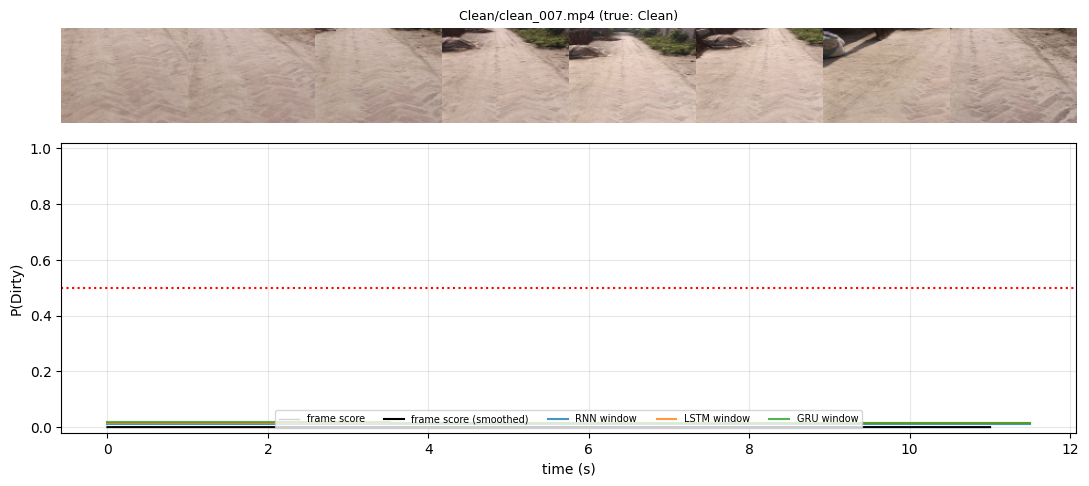

In [ ]:
def segments_from_probs(t, p, thr=0.5, smooth=3, min_dur=1.0, merge_gap=1.0, step=0.5):
    """Contiguous dirty segments [(start_s, end_s, mean_p)] from per-frame probabilities p at times t."""
    t, p = np.asarray(t, float), np.asarray(p, float)
    if len(p) == 0: return []
    ps = np.convolve(np.pad(p, (smooth // 2, smooth - 1 - smooth // 2), mode='edge'), np.ones(smooth) / smooth, mode='valid') if smooth > 1 else p
    on = ps >= thr; segs, i = [], 0
    while i < len(on):
        if on[i]:
            j = i
            while j + 1 < len(on) and on[j + 1]: j += 1
            segs.append([t[i], t[j] + step, float(ps[i:j + 1].mean())]); i = j + 1
        else: i += 1
    merged = []
    for s in segs:
        if merged and s[0] - merged[-1][1] <= merge_gap: merged[-1][1] = s[1]; merged[-1][2] = (merged[-1][2] + s[2]) / 2
        else: merged.append(s)
    return [tuple(s) for s in merged if s[1] - s[0] >= min_dur]

def frame_times(i): return TT[i][0::stride_of(FPS)]
SEGS = {i: segments_from_probs(frame_times(i), FRAME_P[i], step=1 / FPS) for i in range(N)}
flag = pd.DataFrame({'video_id': VID.video_id, 'split': VID.split, 'true': [CLASS_NAMES[v] for v in Y], 'share_of_time_flagged_dirty': [sum(e - s for s, e, _ in SEGS[i]) / max(TT[i][-1] - TT[i][0] + 1 / FPS, 1e-6) for i in range(N)], 'n_segments': [len(SEGS[i]) for i in range(N)]})
print('Share of each video flagged as dirty (a weak proxy; no timestamp ground truth). Held-out videos (validation + test):'); display(flag[flag.split != 'train'].groupby('true').share_of_time_flagged_dirty.describe().round(3))
SEG_CSV = ROOT / 'dirty_segments.csv'
if SEG_CSV.exists():
    gt = pd.read_csv(SEG_CSV); rows = []
    for vid, g in gt.groupby('video_id'):
        if vid not in set(VID.video_id): continue
        i = int(VID.index[VID.video_id == vid][0]); tt_ = frame_times(i); truth = np.zeros(len(tt_), bool)
        for _, r in g.iterrows(): truth |= (tt_ >= r.start_s) & (tt_ < r.end_s)
        pred = np.zeros(len(tt_), bool)
        for s, e, _ in SEGS[i]: pred |= (tt_ >= s) & (tt_ < e)
        tp = (truth & pred).sum(); rows.append(dict(video_id=vid, precision=tp / max(pred.sum(), 1), recall=tp / max(truth.sum(), 1), split=VID.split[i]))
    TSE = pd.DataFrame(rows); print('timestamp evaluation against your annotations (frame level):'); display(TSE.round(3)); TSE.to_csv(DIRS['tables'] / 'timestamp_evaluation.csv', index=False)
else: print('no dirty_segments.csv found: timestamps are shown but not scored.')

def timeline_figure(i, cells=CELLS):
    fig, axs = plt.subplots(2, 1, figsize=(11, 5), gridspec_kw=dict(height_ratios=[1, 2.2])); th = THUMBS[i]; sel = np.linspace(0, len(th) - 1, 8).astype(int)
    strip = np.concatenate([cv2.resize(th[k], (120, 90)) for k in sel], 1); axs[0].imshow(strip); axs[0].axis('off'); axs[0].set_title(f'{VID.video_id[i]} (true: {CLASS_NAMES[Y[i]]})', fontsize=9)
    ft = frame_times(i); axs[1].plot(ft, FRAME_P[i], color='lightgray', lw=1, label='frame score'); axs[1].plot(ft, np.convolve(np.pad(FRAME_P[i], (1, 1), mode='edge'), np.ones(3) / 3, mode='valid'), color='k', lw=1.5, label='frame score (smoothed)')
    for c in cells:
        w = ALL_PROBS[i][c]; axs[1].step([s for s, e in w['spans']] + [w['spans'][-1][1]], list(w['win']) + [w['win'][-1]], where='post', color=cols[CELL_LABEL[c]], alpha=.8, label=f'{CELL_LABEL[c]} window')
    for s, e, p in SEGS[i]: axs[1].axvspan(s, e, color='red', alpha=.15)
    axs[1].axhline(0.5, color='r', ls=':'); axs[1].set_ylim(-0.02, 1.02); axs[1].set_xlabel('time (s)'); axs[1].set_ylabel('P(Dirty)'); axs[1].legend(fontsize=7, ncol=5, loc='lower center'); axs[1].grid(alpha=.3)
    plt.tight_layout(); return fig
held = [i for i in range(N) if VID.split[i] != 'train']; ex = [i for i in held if Y[i] == 1][:2] + [i for i in held if Y[i] == 0][:2]
for i in ex: fig = timeline_figure(i); savefig(f'timeline_{i}'); plt.show()

### 12.3 Transcoding for playback

Phone videos are often HEVC or very large; browsers cannot always play them. For the search interface and the GitHub export, small H.264 copies (480 p, no audio, so no voices are stored) are made with `ffmpeg`. The classification always uses the original videos.

In [ ]:
WEB_DIR = LOCAL / 'web'
def to_web(src, dst):
    dst = Path(dst); dst.parent.mkdir(parents=True, exist_ok=True)
    if dst.exists(): return str(dst)
    r = subprocess.run(['ffmpeg', '-y', '-loglevel', 'error', '-i', str(src), '-vf', 'scale=-2:480', '-c:v', 'libx264', '-preset', 'veryfast', '-crf', '28', '-an', '-movflags', '+faststart', str(dst)], capture_output=True)
    return str(dst) if r.returncode == 0 and dst.exists() else str(src)
if TRANSCODE_FOR_WEB and shutil.which('ffmpeg'):
    INDEX['play_path'] = [to_web(r.path, WEB_DIR / Path(r.video_id).parent / (Path(r.video_id).stem + '.mp4')) for r in tqdm(INDEX.itertuples(), total=len(INDEX), desc='transcoding')]
else: INDEX['play_path'] = INDEX.path
print('playable copies:', int((INDEX.play_path != INDEX.path).sum()), 'of', len(INDEX), '| total size (MB):', round(sum(Path(p).stat().st_size for p in INDEX.play_path) / 2**20, 1))

transcoding:   0%|          | 0/69 [00:00<?, ?it/s]

playable copies: 69 of 69 | total size (MB): 19.6


### 12.4 Search interface

A Gradio app with two tabs.

* **Search the index:** choose a category (Clean, Dirty or All), the model that provides the index, a minimum confidence and a split filter. The matching videos are listed, sorted by confidence; pick one to **play it** and to see its **timeline** (frame scores, window scores and the dirty segments with timestamps).
* **Classify a new video:** upload a video; its frames are extracted and the three recurrent models and the frame baseline give a label, the confidence and the timeline.

The notebook also provides the same search as a plain Python function (`search_videos`) that works without Gradio.

,video_id,predicted,confidence,true_label,split,duration_s
0,Dirty/dirty_020.mp4,Dirty,0.991396,Dirty,train,7.213156
1,Dirty/dirty_011.mp4,Dirty,0.991310,Dirty,train,9.506689
2,Dirty/dirty_005.mp4,Dirty,0.991155,Dirty,train,10.771056
3,Dirty/dirty_006.mp4,Dirty,0.991101,Dirty,train,7.611833
4,Dirty/dirty_010.mp4,Dirty,0.990999,Dirty,train,10.337589
5,Dirty/dirty_019.mp4,Dirty,0.990883,Dirty,train,7.811422
6,Dirty/dirty_023.mp4,Dirty,0.990868,Dirty,train,8.575878
7,Dirty/dirty_001.mp4,Dirty,0.990841,Dirty,train,8.708822
8,Dirty/dirty_012.mp4,Dirty,0.990706,Dirty,train,8.309956
9,Dirty/dirty_013.mp4,Dirty,0.990617,Dirty,val,7.046933


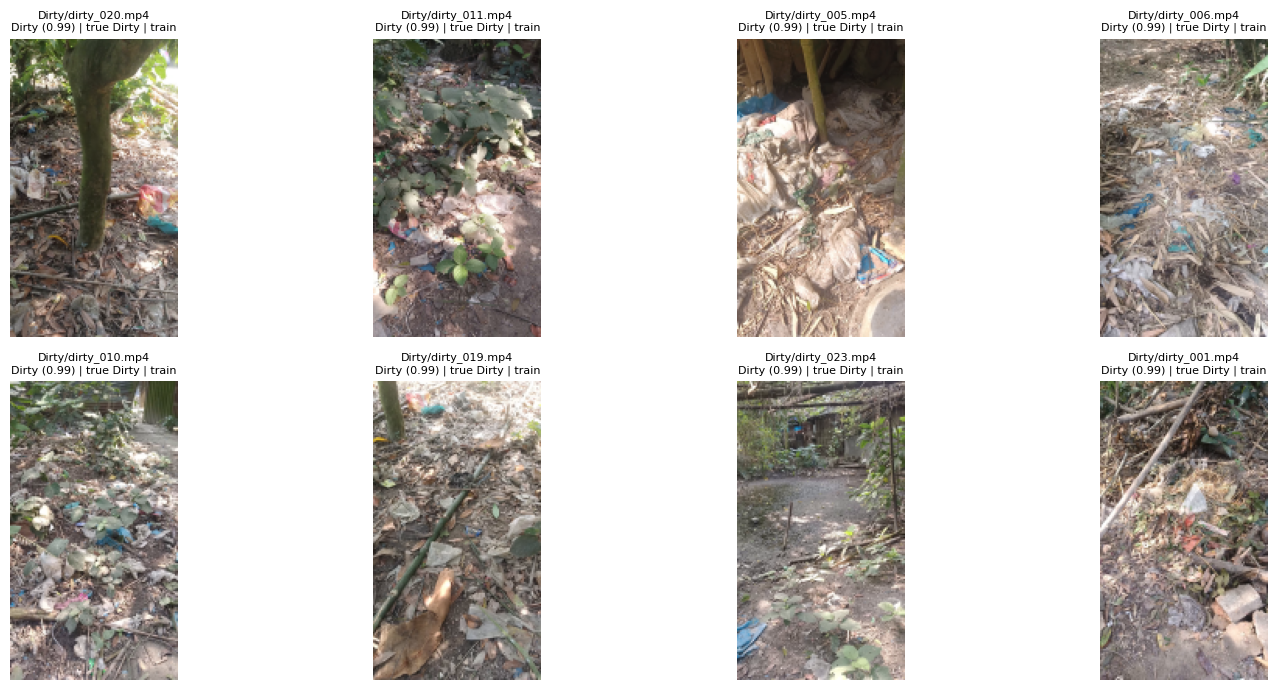

In [ ]:
PCOL = {'RNN': 'p_rnn', 'LSTM': 'p_lstm', 'GRU': 'p_gru', 'Frame average': 'p_frame'}
def search_videos(category='Dirty', model=CELL_LABEL[INDEX_CELL], min_conf=0.5, split='all', limit=50):
    p = INDEX[PCOL[model]].values; pred = (p >= 0.5).astype(int); conf = np.where(pred == 1, p, 1 - p); m = conf >= min_conf
    if category != 'All': m &= pred == (1 if category == 'Dirty' else 0)
    if split != 'all': m &= (INDEX.split == split).values
    res = INDEX[m].assign(predicted=np.array(CLASS_NAMES)[pred[m]], confidence=conf[m]).sort_values('confidence', ascending=False).head(limit)
    return res[['video_id', 'predicted', 'confidence', 'true_label', 'split', 'duration_s']].reset_index(drop=True)
display(search_videos('Dirty', min_conf=0.8).head(10))
def show_results(df, n=8):
    fig, axs = plt.subplots(2, 4, figsize=(16, 7)); axs = axs.ravel()
    for ax in axs: ax.axis('off')
    for ax, (_, r) in zip(axs, df.head(n).iterrows()):
        i = int(VID.index[VID.video_id == r.video_id][0]); ax.imshow(THUMBS[i][len(THUMBS[i]) // 2]); ax.set_title(f'{r.video_id}\n{r.predicted} ({r.confidence:.2f}) | true {r.true_label} | {r.split}', fontsize=8)
    plt.tight_layout(); plt.show()
show_results(search_videos('Dirty', min_conf=0.8))

In [ ]:
LAUNCH_GRADIO = True
import gradio as gr
VIDX = {r.video_id: i for i, r in enumerate(VID.itertuples())}

def _segments_df(i): return pd.DataFrame([dict(start_s=round(s, 1), end_s=round(e, 1), mean_P_dirty=round(p, 2)) for s, e, p in SEGS[i]], columns=['start_s', 'end_s', 'mean_P_dirty'])
def ui_search(category, model, min_conf, split):
    df = search_videos(category, model, min_conf, split); ch = [f'{r.video_id} | {r.predicted} {r.confidence:.2f} | true {r.true_label} | {r.split}' for r in df.itertuples()]
    return df, gr.Dropdown(choices=ch, value=ch[0] if ch else None), f'{len(df)} video(s) found'
def ui_show(choice):
    if not choice: return None, None, pd.DataFrame(columns=['start_s', 'end_s', 'mean_P_dirty'])
    i = VIDX[choice.split(' | ')[0]]; fig = timeline_figure(i); path = INDEX.play_path.iloc[i]; plt.close(fig); return path, fig, _segments_df(i)

def ui_classify(path):
    if not path: return 'no video', None, pd.DataFrame(columns=['start_s', 'end_s', 'mean_P_dirty'])
    e = extract_video(path, max_seconds=120)
    if len(e['F']) < 2: return 'could not read frames from this video', None, pd.DataFrame(columns=['start_s', 'end_s', 'mean_P_dirty'])
    Ft = torch.from_numpy(e['F'].astype(np.float32)).to(DEVICE); pr = ensemble_probs(Ft, e['t']); s = stride_of(FPS); ft = e['t'][0::s]
    pf = FRAME_CLF.predict_proba(FRAME_SC.transform(e['F'].astype(np.float32)[0::s]))[:, 1]
    lines = [f"{CELL_LABEL[c]}: {'Dirty' if pr[c]['p'][1] >= .5 else 'Clean'} (P(Dirty) = {pr[c]['p'][1]:.2f})" for c in CELLS] + [f"Frame average: {'Dirty' if pf.mean() >= .5 else 'Clean'} (P(Dirty) = {pf.mean():.2f})"]
    fig, ax = plt.subplots(figsize=(10, 3.4)); ax.plot(ft, pf, color='k', lw=1, label='frame score')
    for c in CELLS: w = pr[c]; ax.step([a for a, b in w['spans']] + [w['spans'][-1][1]], list(w['win']) + [w['win'][-1]], where='post', color=cols[CELL_LABEL[c]], label=f'{CELL_LABEL[c]} window')
    segs = segments_from_probs(ft, pf, step=1 / FPS)
    for a, b, _ in segs: ax.axvspan(a, b, color='red', alpha=.15)
    ax.axhline(0.5, color='r', ls=':'); ax.set_ylim(-0.02, 1.02); ax.set_xlabel('time (s)'); ax.set_ylabel('P(Dirty)'); ax.legend(fontsize=7, ncol=4); ax.grid(alpha=.3); plt.tight_layout(); plt.close(fig)
    return '\n'.join(lines), fig, pd.DataFrame([dict(start_s=round(a, 1), end_s=round(b, 1), mean_P_dirty=round(p, 2)) for a, b, p in segs], columns=['start_s', 'end_s', 'mean_P_dirty'])

with gr.Blocks(title='Clean / Dirty video index') as demo:
    gr.Markdown('## Clean / Dirty video index\nSearch the indexed videos by label, or classify a new video. Labels come from RNN / LSTM / GRU models on ResNet-50 frame features.')
    with gr.Tab('Search the index'):
        with gr.Row():
            cat = gr.Radio(['Dirty', 'Clean', 'All'], value='Dirty', label='Category'); mdl = gr.Dropdown(list(PCOL), value=CELL_LABEL[INDEX_CELL], label='Index model')
            conf = gr.Slider(0.5, 0.99, value=0.5, step=0.01, label='Minimum confidence'); spl = gr.Dropdown(['all', 'train', 'val', 'test'], value='all', label='Split (training videos are optimistic)')
        btn = gr.Button('Search'); info = gr.Markdown(); tab = gr.Dataframe(label='Matching videos'); pick = gr.Dropdown(label='Select a video'); vid = gr.Video(label='Video')
        plot = gr.Plot(label='Timeline: P(Dirty) over time'); seg = gr.Dataframe(label='Dirty segments (timestamps in seconds)')
        btn.click(ui_search, [cat, mdl, conf, spl], [tab, pick, info]); pick.change(ui_show, [pick], [vid, plot, seg])
    with gr.Tab('Classify a new video'):
        up = gr.Video(label='Upload a video', sources=['upload']); go = gr.Button('Classify'); out_t = gr.Textbox(label='Predictions', lines=5); out_p = gr.Plot(); out_s = gr.Dataframe(label='Dirty segments')
        go.click(ui_classify, [up], [out_t, out_p, out_s])
if LAUNCH_GRADIO: demo.launch(share=True, debug=False, allowed_paths=[str(LOCAL), str(ROOT)])

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://f4ac08f933fada063e.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
